# Estatística Geral

## Probabilidade


### Axiomas:

Dado um espaço amostral, Ω, suponha que estamos estudando um evento A. 
A probabilidade do evento A ocorrer é denotada por P(A). A função P(A) só será uma probabilidade se ela satisfaz três condições básicas:
- 0 < P(A) < 1
- P(Ω) = 1
- P(A1 U A2 U A3 U...) = P(A1)+P(A2)+P(A3)+..., se os eventos A1, A2,... forem disjuntos (isto é, mutuamente exclusivos).

### Atribuição de probabilidade de um evento por meio das características teóricas do experimento (Visão clássica):

Seja E um experimento e Ω um espaço amostral, a ele associado, composto de n pontos amostrais. Define-se a probabilidade da ocorrência de um evento A, indicada por P(A), como sendo a relação entre o número de pontos favoráveis (f) à realização do evento A e o número total de pontos (n), ou seja:

$$P(A) = \frac{f}{n} = \frac{\text{nº de pontos amostrais favoráveis a } A}{\text{nº total de pontos amostrais}}$$

Por exemplo, ao lançarmos uma moeda equilibrada sabemos que, teoricamente, cada face tem a mesma probabilidade de ocorrência, isto é, P(C) = P( C ) = ½.

### Atribuição de probabilidade de um evento por meio das freqüências de ocorrências (Visão frequentista):

Se o fenômeno sob análise puder ser repetido indefinidamente, nas mesmas condições e de forma independente (sem
que uma repetição afete a seguinte), então, se A é um evento de interesse, a probabilidade de ocorrência de A é dada por:

$$P(A) \approx \frac{n_A}{n} = \frac{\text{nº de vezes em que } A \text{ ocorreu}}{\text{nº total de repetições do experimento}}$$

A aproximação fica melhor à medida que o número de repetições $n$ cresce.

Exemplo 1: De acordo com o IBGE (1988), a distribuição dos suicídios ocorridos no Brasil em 1986, segundo a causa atribuída foi a seguinte:

    Causa do suicídio       Freqüência
    Alcoolismo              (A) 263
    Dificuldade financeira  (F) 198
    Doença mental           (M) 700
    Outro tipo de doença    (O) 189
    Desilusão amorosa       (D) 416
    Outras causas           (C) 217
    Total                   1983

Ao selecionarmos aleatoriamente uma das pessoas que tentaram suicídio, determine a probabilidade de que a causa atribuída tenha sido:
- Desilusão amorosa: P(D) = 416/1983 = 0,2097

- Doença mental: P(M) = 700/1983 = 0,3530

In [2]:
DATASET = [263, 198, 700, 189, 416, 217]

In [6]:
P_D = DATASET[4] / sum(DATASET)
P_D

0.20978315683308119

### Interseção de eventos:

A interseção de dois eventos A e B corresponde à ocorrência simultânea dos eventos A e B. Contém todos os pontos do espaço amostral comuns a A e B.

O diagrama abaixo destaca $A \cap B$:

In [1]:
# Funções auxiliares usadas para desenhar os diagramas e gráficos deste notebook
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm


def virgula(ax):
    """Mostra os números dos eixos com vírgula decimal."""
    fmt = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def diagrama_venn(destaque):
    """Diagrama de Venn de dois eventos A e B no espaço amostral Ω.
    destaque: 'intersecao', 'uniao', 'disjuntos' ou 'complementares'."""
    fig, ax = plt.subplots(figsize=(4, 2.6))
    cinza = "0.65"
    if destaque == "complementares":
        ax.add_patch(Rectangle((0, 0), 10, 6, fc=cinza, ec="k", lw=1.5))
        ax.add_patch(Ellipse((6.5, 3.2), 3.6, 2.4, fc="white", ec="k"))
        ax.text(0.4, 5.1, "A", fontsize=12)
        ax.text(7.9, 4.5, "B", fontsize=12)
    elif destaque == "disjuntos":
        ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, lw=1.5))
        ax.add_patch(Ellipse((3, 3.6), 3, 2.4, fc="0.45", ec="k"))
        ax.add_patch(Ellipse((7.2, 2.0), 3, 2.0, fc="0.8", ec="k"))
        ax.text(1.0, 4.9, "A", fontsize=12)
        ax.text(8.9, 0.6, "B", fontsize=12)
    else:
        ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, lw=1.5))
        if destaque == "uniao":
            ax.add_patch(Ellipse((3.9, 3), 4.2, 3, fc=cinza, ec="none"))
            ax.add_patch(Ellipse((6.1, 3), 4.2, 3, fc=cinza, ec="none"))
        elif destaque == "intersecao":
            recorte = Ellipse((3.9, 3), 4.2, 3, fill=False, ec="none")
            ax.add_patch(recorte)
            miolo = Ellipse((6.1, 3), 4.2, 3, fc="0.45", ec="none")
            ax.add_patch(miolo)
            miolo.set_clip_path(recorte)
        ax.add_patch(Ellipse((3.9, 3), 4.2, 3, fill=False, ec="k"))
        ax.add_patch(Ellipse((6.1, 3), 4.2, 3, fill=False, ec="k"))
        ax.text(1.0, 4.8, "A", fontsize=12)
        ax.text(8.6, 4.8, "B", fontsize=12)
    ax.text(0.3, 0.3, "Ω", fontsize=12)
    ax.set_xlim(-0.2, 10.2)
    ax.set_ylim(-0.2, 6.2)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.show()


def arvore(ramos, largura_notas=2.2, figsize=(6.5, 4)):
    """Desenha uma árvore de probabilidades.
    Cada ramo é uma tupla (rótulo, probabilidade em texto, sub-ramos, anotação)."""
    fig, ax = plt.subplots(figsize=figsize)
    contador = [0]

    def posicionar(ramo, nivel):
        rotulo, prob, sub, nota = ramo
        filhos = [posicionar(r, nivel + 1) for r in sub]
        if filhos:
            y = np.mean([f["y"] for f in filhos])
        else:
            y = -contador[0]
            contador[0] += 1
        return {"x": nivel, "y": y, "rotulo": rotulo, "prob": prob, "nota": nota, "filhos": filhos}

    nos = [posicionar(r, 1) for r in ramos]
    y_raiz = np.mean([n["y"] for n in nos])
    nivel_max = [1]

    def desenhar(x0, y0, filhos):
        for n in filhos:
            nivel_max[0] = max(nivel_max[0], n["x"])
            ax.plot([x0 + 0.06, n["x"] - 0.14], [y0, n["y"]], color="0.35", lw=1)
            desce = n["y"] < y0  # ramo descendente: rótulo abaixo da linha
            ax.text((x0 + n["x"]) / 2 - 0.1, (y0 + n["y"]) / 2 + (-0.1 if desce else 0.1), n["prob"],
                    ha="center", va="top" if desce else "bottom", fontsize=9, color="tab:blue")
            ax.text(n["x"], n["y"], n["rotulo"], ha="center", va="center", fontsize=11)
            if n["nota"]:
                ax.text(n["x"] + 0.3, n["y"], n["nota"], va="center", fontsize=9)
            desenhar(n["x"], n["y"], n["filhos"])

    desenhar(0, y_raiz, nos)
    ax.plot(0, y_raiz, "o", color="0.35", ms=4)
    ax.set_xlim(-0.2, nivel_max[0] + largura_notas)
    ax.set_ylim(-contador[0] + 0.5, 0.6)
    ax.axis("off")
    plt.show()


def area_normal(a, b, titulo, mu=0, sigma=1, figsize=(5, 2.6)):
    """Sombreia a área entre a e b sob a curva normal (use np.inf para caudas)."""
    x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(x, norm.pdf(x, mu, sigma), color="tab:blue")
    xs = np.linspace(max(a, x[0]), min(b, x[-1]), 300)
    ax.fill_between(xs, norm.pdf(xs, mu, sigma), color="tab:blue", alpha=0.3)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    virgula(ax)
    plt.show()

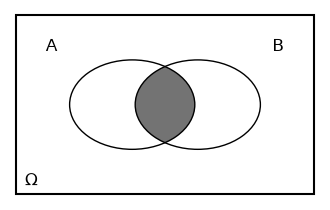

In [2]:
diagrama_venn("intersecao")

### Evento disjuntos ou mutuamente exclusivos:

Dois eventos A e B são chamados disjuntos ou mutuamente exclusivos quando não puderem ocorrer juntos, ou seja, quando não têm elementos em comum, isto é, a inteseção de eventos é igual ao conjunto vazio.

No diagrama abaixo, $A$ e $B$ não se sobrepõem, ou seja, $A \cap B = \varnothing$:

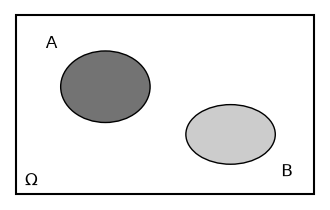

In [3]:
diagrama_venn("disjuntos")

### União de eventos:

A união dos eventos A e B equivale à ocorrência de A, ou de B, ou de ambos, ou seja, a ocorrência de pelo menos um dos eventos A ou B.

O diagrama abaixo destaca $A \cup B$:

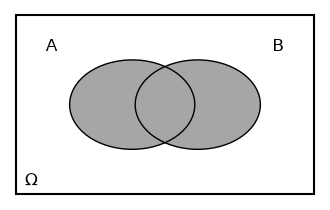

In [4]:
diagrama_venn("uniao")

Para encontrar a união de dois eventos deve-se utilizar a seguinte fórmula:

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

### Eventos complementares:

Dois eventos A e B são complementares se sua união corresponde ao espaço amostral e sua interseção é vazia. O diagrama a seguir ilustra tal situação.

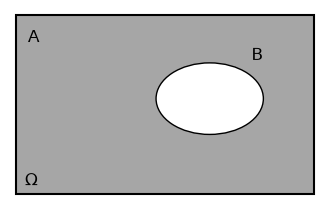

In [5]:
diagrama_venn("complementares")

- Para dois eventos A e B serem complementares: 
$A \cup B = \Omega$ e $A \cap B = \varnothing$.

- Além disso, o complementar do evento A ocorre quando o evento A não ocorrer, ou seja: 

$A^c = B$ e $B^c = A$

- Pode-se observar também que: 

$P(A) = 1 - P(B)$ e $P(A^c) = P(B)$

Exemplo:

Numa amostra de 1000 pessoas falecidas, cada uma foi classificada pelo hábito de fumar e pela causa da morte:

| Fumante | Câncer (C) | Doença cardíaca (D) | Outras causas (O) | Total |
|---|---|---|---|---|
| Sim (F) | 135 | 310 | 205 | 650 |
| Não ($F^c$) | 55 | 155 | 140 | 350 |
| Total | 190 | 465 | 345 | 1000 |

Sorteando ao acaso uma dessas pessoas, qual é a probabilidade de que ela:

- a) fosse fumante;
- b) tenha morrido de câncer;
- c) não fosse fumante e tenha morrido de doença cardíaca;
- d) fosse fumante ou tenha morrido de outras causas?

Resolução:

- a) $P(F) = \dfrac{650}{1000} = 0{,}65$
- b) $P(C) = \dfrac{190}{1000} = 0{,}19$
- c) $P(F^c \cap D) = \dfrac{155}{1000} = 0{,}155$
- d) $P(F \cup O) = P(F) + P(O) - P(F \cap O) = \dfrac{650}{1000} + \dfrac{345}{1000} - \dfrac{205}{1000} = 0{,}79$

In [3]:
DATASET = [[135, 310, 205, 650],[55, 155, 140, 350],[190, 465, 345, 1000]]

A = DATASET[0][3]/DATASET[2][3]
print(A)
B = DATASET[2][0]/DATASET[2][3]
print(B)
C = DATASET[1][1]/DATASET[2][3]
print(C)
D = (DATASET[0][3]/DATASET[2][3]) + (DATASET[2][2]/DATASET[2][3]) - (DATASET[0][2]/DATASET[2][3])
print(D)

0.65
0.19
0.155
0.79


### Probabilidade condicional:

A probabilidade condicional de A dado B é a probabilidade de ocorrência do evento A, sabido que o evento B já ocorreu. Pode ser determinada dividindo-se a probabilidade de ocorrência de ambos os eventos A e B pela probabilidade de ocorrência do evento B, como é mostrado a seguir:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \quad P(B) > 0$$

### Regra do produto:

$$P(A \cap B) = P(A \mid B) \cdot P(B), \quad P(B) > 0$$

### Independência de eventos:

Dois eventos A e B são independentes se a ocorrência de um deles não afeta a
probabilidade de ocorrência do outro, ou seja:

$$P(A \mid B) = P(A) \quad \text{e} \quad P(B \mid A) = P(B)$$

Se dois eventos A e B são independentes então:

$$P(A \cap B) = P(A) \cdot P(B)$$

### Teorema da probabilidade total:

Sejam A1, A2, A3... An eventos dois a dois disjuntos que formam uma partição do espaço amostral, isto é,

$$\bigcup_{i=1}^{n} A_i = \Omega$$

e assuma que P(Ai)>0 para i=1, 2, 3,...n. Então, para qualquer evento B, temos que

$$P(B) = P(A_1 \cap B) + P(A_2 \cap B) + \cdots + P(A_n \cap B)$$

Aplicando a regra do produto temos que

$$P(B) = \sum_{i=1}^{n} P(A_i) \cdot P(B \mid A_i)$$

### Teorema de Bayes:

Sejam A1, A2, A3... An eventos que formam uma partição do espaço amostral, e assuma que P(Ai)>0 para todo i. Então, para qualquer evento B tal que P(B)>0, temos que

$$P(A_i \mid B) = \frac{P(A_i \cap B)}{P(B)} = \frac{P(B \mid A_i) \cdot P(A_i)}{P(B \mid A_1) \cdot P(A_1) + P(B \mid A_2) \cdot P(A_2) + \cdots + P(B \mid A_n) \cdot P(A_n)}$$

Para verificar o teorema de Bayes, basta notar que

$$P(A_i \cap B) = P(B \cap A_i)$$

e que, por sua vez,

$$P(B \mid A_i) \cdot P(A_i) = P(A_i \mid B) \cdot P(B)$$

o que garante o numerador. O denominador segue da aplicação do teorema da probabilidade total para B.

### Árvore de probabilidades:

é um diagrama que consiste em representar os eventos e as probabilidades condicionais associadas às realizações. Cada um dos caminhos da árvore indica uma possível ocorrência ou interseção de eventos.
- Exemplo:
    Suponha que você é o gerente de uma fábrica de sorvetes. Você sabe que 20% de todo o leite que utiliza na fabricação dos sorvetes provém da fazenda F1, 30% são de uma outra fazenda F2 e 50% de uma fazenda F3. Um órgão de fiscalização inspecionou as fazendas de surpresa, e observou que 20% do leite produzido por F1 estava adulterado por adição de água, enquanto que para F2 e F3, essa proporção era de 5% e 2%, respectivamente. Na indústria de sorvetes que você gerencia os galões de leite são armazenados em um refrigerador sem identificação das fazendas. Para um galão escolhido ao acaso, calcule:
    a) A probabilidade de que o galão contenha leite adulterado.
    b) A probabilidade de que o galão tenha vindo da fazenda F3, sabendo que contém leite não adulterado.

    Resolução:
    Observe que o diagrama de Venn a seguir ilustra os três eventos associados as fazendas (F1, F2 e F3) e ao leite adulterado (A) ou não adulterado (Ac):

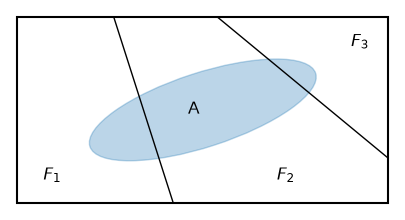

In [6]:
# Partição do espaço amostral pelas fazendas F1, F2 e F3 e o evento A (leite adulterado)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.add_patch(Rectangle((0, 0), 10, 5, fill=False, lw=1.5))
ax.plot([2.6, 4.2], [5, 0], color="k", lw=1)
ax.plot([5.4, 10], [5, 1.2], color="k", lw=1)
ax.add_patch(Ellipse((5.0, 2.5), 6.4, 2.0, angle=18, fc="tab:blue", alpha=0.3, ec="tab:blue"))
ax.text(4.6, 2.4, "A", fontsize=12)
ax.text(0.7, 0.6, "$F_1$", fontsize=12)
ax.text(7.0, 0.6, "$F_2$", fontsize=12)
ax.text(9.0, 4.2, "$F_3$", fontsize=12)
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-0.2, 5.2)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

    Se denotarmos por A o evento “o leite está adulterado”, temos que P(A|F1)=0,20, P(A|F2)=0,05 e P(A|F3)=0,02. Além disso, a probabilidade do leite ser produzido por cada uma das fazendas (F1, F2 e F3) é denotada por P(F1)=0,2, P(F2)=0,3 e P(F3)=0,5. A partir daí, podemos construir a árvore de probabilidades da seguinte maneira:

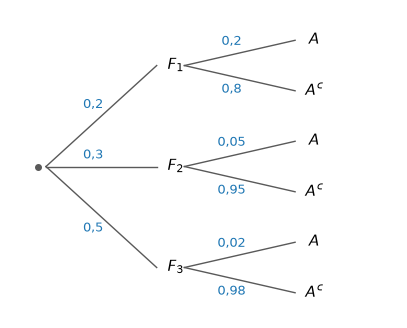

In [7]:
# Árvore de probabilidades: fazendas (F1, F2, F3) e leite adulterado (A) ou não (Aᶜ)
arvore([
    ("$F_1$", "0,2", [("$A$", "0,2", [], None), ("$A^c$", "0,8", [], None)], None),
    ("$F_2$", "0,3", [("$A$", "0,05", [], None), ("$A^c$", "0,95", [], None)], None),
    ("$F_3$", "0,5", [("$A$", "0,02", [], None), ("$A^c$", "0,98", [], None)], None),
], largura_notas=0.6, figsize=(5, 4))

a) Pelo teorema da probabilidade total:

$$P(A) = P(A \mid F_1) \cdot P(F_1) + P(A \mid F_2) \cdot P(F_2) + P(A \mid F_3) \cdot P(F_3)$$

$$P(A) = 0{,}20 \cdot 0{,}2 + 0{,}05 \cdot 0{,}3 + 0{,}02 \cdot 0{,}5 = 0{,}04 + 0{,}015 + 0{,}01 = 0{,}065$$

b) Pelo teorema de Bayes, com $A^c$ = "leite não adulterado" e $P(A^c) = 1 - P(A)$:

$$P(F_3 \mid A^c) = \frac{P(A^c \mid F_3) \cdot P(F_3)}{1 - P(A)} = \frac{0{,}98 \cdot 0{,}5}{1 - 0{,}065} = \frac{0{,}49}{0{,}935} \approx 0{,}5241$$

### Exercícios:

1. Na Tabela 1, temos os dados referentes a alunos matriculados em quatro cursos de uma universidade em dado ano.

**Tabela 1** – Alunos matriculados em quatro cursos, por sexo.

| Curso | Masculino | Feminino | Total |
|---|---|---|---|
| Computação | 70 | 40 | 110 |
| Matemática | 15 | 15 | 30 |
| Estatística | 10 | 20 | 30 |
| Ciências Atuariais | 20 | 10 | 30 |
| Total | 115 | 85 | 200 |

Selecionado-se ao acaso um aluno do conjunto desses quatro cursos determine a probabilidade:
a) Que o aluno seja do sexo masculino.
b) Que o aluno esteja matriculado no curso de Estatística.
c) Que o aluno seja do sexo feminino e matriculado em Matemática.
d) Que o aluno seja do sexo masculino ou matriculado em Ciências Atuariais.
Respostas: a) 0,575 b) 0,15 c)0,075 d)0,625

In [7]:
F_M_T = 115
F_T = 200
P_M_T = F_M_T/F_T
print("a) \f",P_M_T)

a)  0.575


In [8]:
F_E_T = 30
F_T = 200
P_E_T = F_E_T/F_T
print("b) \f",P_E_T)

b)  0.15


In [9]:
F_F_M = 15
F_T = 200
P_F_M = F_F_M/F_T
print("c) \f",P_F_M)

c)  0.075


In [10]:
F_M_T = 115
F_T = 200
P_M_T = F_M_T/F_T

F_C_T = 30
P_C_T = F_C_T/F_T

F_M_C = 20
P_M_C = F_M_C/F_T

P_M_ou_C = P_M_T + P_C_T - P_M_C
print("d) \f",P_M_ou_C)

d)  0.625


2. Uma determinada peça é manufaturada por três fábricas A, B e C. Sabe-se que a fábrica A produz o dobro de peças que B, e B e C produziram o mesmo número de peças (durante um período de produção especificado). Sabe-se também que 2% das peças produzidas por A e 2% das peças produzidas por B são defeituosas, enquanto 4% daquelas produzidas por C são defeituosas. Todas as peças produzidas são colocadas em um depósito, e depois uma peça é extraída ao acaso.
a) Qual é a probabilidade de que essa peça seja defeituosa?
b) Qual é a probabilidade de que a peça tenha sido produzida pela fábrica B,
sabendo-se que é perfeita?
Dica: Utilize a árvore de probabilidades.
Respostas: a) 0,025 b) 0,251

Árvore de probabilidades do exercício 2 (o produto ao longo de cada caminho é a probabilidade da interseção):

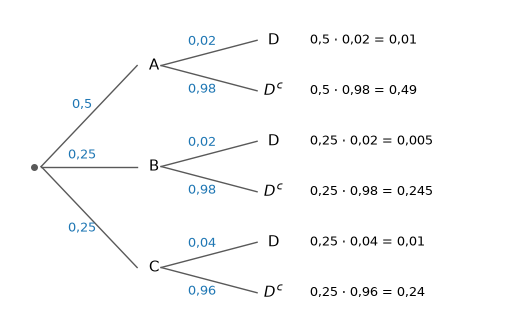

In [8]:
# Árvore de probabilidades do exercício 2: fábrica (A, B, C) e peça defeituosa (D) ou não (Dᶜ)
arvore([
    ("A", "0,5", [("D", "0,02", [], "0,5 · 0,02 = 0,01"), ("$D^c$", "0,98", [], "0,5 · 0,98 = 0,49")], None),
    ("B", "0,25", [("D", "0,02", [], "0,25 · 0,02 = 0,005"), ("$D^c$", "0,98", [], "0,25 · 0,98 = 0,245")], None),
    ("C", "0,25", [("D", "0,04", [], "0,25 · 0,04 = 0,01"), ("$D^c$", "0,96", [], "0,25 · 0,96 = 0,24")], None),
], largura_notas=2.0, figsize=(6.5, 4))

In [11]:
P_A_D = 0.01
P_B_D = 0.005
P_C_D = 0.01
P_D = P_A_D + P_B_D + P_C_D
print("a) \f",P_D)

a)  0.025


In [12]:
P_B_Dc = 0.245
P_Dc = 1 - 0.025   # P_Dc = 1 - P_D
P_B_dado_Dc = P_B_Dc / P_Dc
print("b) \f",P_B_dado_Dc)

b)  0.2512820512820513


4. Na tabela abaixo, os números que aparecem são probabilidades relacionadas com a ocorrência de A, B, A e B, etc. Assim, P(A) = 0,10, enquanto P(A e B) = 0,04.

| | $B$ | $B^c$ | Total |
|---|---|---|---|
| $A$ | 0,04 | 0,06 | 0,10 |
| $A^c$ | 0,08 | 0,82 | 0,90 |
| Total | 0,12 | 0,88 | 1,00 |

Verifique se A e B são independentes.
Resposta: Como P(AeB) ≠ P(A).P(B), A e B não são independentes.

In [16]:
P_A = 0.1
P_B = 0.12
P_A_B = 0.4

# Para que A e B sejam independentes: P_A_B = P_A * P_B

if P_A_B == P_A * P_B:
    print("A e B são independentes pois P(AeB) = P(A).P(B)")
else:
    print("A e B não são independentes pois P(AeB) ≠ P(A).P(B)")

A e B não são independentes pois P(AeB) ≠ P(A).P(B)


5. Você entrega a seu amigo uma carta, destinada à sua namorada, para ser colocada no correio. Entretanto, ele pode se esquecer com probabilidade 0,1. Se não se esquecer, a probabilidade de que o correio extravie a carta é de 0,1. Finalmente, se foi enviada pelo correio a probabilidade de que a namorada não a receba é de 0,1.
a) Sua namorada não recebeu a carta, qual a probabilidade de seu amigo ter
esquecido?
b) Avalie as possibilidades desse namoro continuar se a comunicação depender
das cartas enviadas.
Dica: Utilize a árvore de probabilidades. Ela ‘cresce’ mais para um lado do que para o outro. Não se preocupe!
Respostas: a) 0,369 b) 0,729

Eventos: $A$ = o amigo esquece a carta; $B$ = o correio extravia a carta; $C$ = a carta enviada não chega à namorada ($A^c$, $B^c$ e $C^c$ são os complementares). A árvore está na célula abaixo.

$$P(\text{receber}) = 0{,}9^3 = 0{,}729 \qquad P(\text{não receber}) = 1 - 0{,}9^3 = 0{,}271$$

Se o amigo esquece, a carta certamente não chega, então $P(A \cap \text{não receber}) = P(A)$ e

$$P(A \mid \text{não receber}) = \frac{P(A)}{P(\text{não receber})} = \frac{0{,}1}{0{,}271} \approx 0{,}369$$

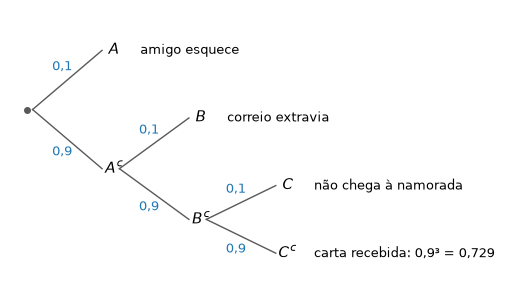

In [9]:
# Árvore de probabilidades do exercício 5: só há ramificação quando a carta segue adiante
arvore([
    ("$A$", "0,1", [], "amigo esquece"),
    ("$A^c$", "0,9", [
        ("$B$", "0,1", [], "correio extravia"),
        ("$B^c$", "0,9", [
            ("$C$", "0,1", [], "não chega à namorada"),
            ("$C^c$", "0,9", [], "carta recebida: 0,9³ = 0,729"),
        ], None),
    ], None),
], largura_notas=2.6, figsize=(6.5, 3.6))

## Variáveis aleatórias discretas

Uma variável aleatória é discreta se assume valores que podem ser contados, ou seja, se houver um número finito ou contável de resultados possíveis que possam ser enumerados.

### Distribuição de probabilidade:

#### Exemplo:
Uma companhia analisa diariamente o número de vendas de seus novos funcionários durante um período de testes de cem dias. Os resultados para um novo funcionário são apresentados abaixo por meio de uma tabela de
frequências:

| Vendas por dia ($x$) | Número de dias (frequência) |
|---|---|
| 0 | 16 |
| 1 | 19 |
| 2 | 15 |
| 3 | 21 |
| 4 | 9 |
| 5 | 10 |
| 6 | 8 |
| 7 | 2 |

Para organizar a distribuição de probabilidades para a variável aleatória discreta X:
Número de vendas por dia, onde x = 0, 1, 2, 3, 4, 5, 6, 7, precisamos calcular as probabilidades de ocorrência de cada um desses valores utilizando a frequência com que eles ocorrem, ou seja:

| Vendas por dia ($x$) | Número de dias (frequência) | $P(X = x)$ |
|---|---|---|
| 0 | 16 | 16/100 = 0,16 |
| 1 | 19 | 19/100 = 0,19 |
| 2 | 15 | 0,15 |
| 3 | 21 | 0,21 |
| 4 | 9 | 0,09 |
| 5 | 10 | 0,10 |
| 6 | 8 | 0,08 |
| 7 | 2 | 0,02 |
| Total | 100 | 1,00 |

É interessante observar que cada probabilidade está no intervalo de 0 a 1 e que a soma de todas as probabilidades é 1.

A partir daí, construímos a distribuição de probabilidades enumerando cada valor que a variável x assume com a sua probabilidade correspondente:

| $x$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $P(X = x)$ | 0,16 | 0,19 | 0,15 | 0,21 | 0,09 | 0,10 | 0,08 | 0,02 |

Gráfico da distribuição de probabilidades:

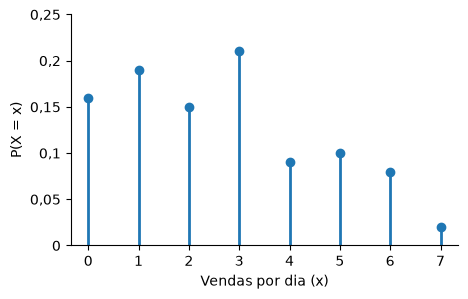

In [10]:
# Distribuição de probabilidades do número de vendas por dia
x_graf = np.arange(8)
p_graf = np.array([16, 19, 15, 21, 9, 10, 8, 2]) / 100
fig, ax = plt.subplots(figsize=(5, 3))
ax.vlines(x_graf, 0, p_graf, color="tab:blue", lw=2)
ax.plot(x_graf, p_graf, "o", color="tab:blue")
ax.set_xlabel("Vendas por dia (x)")
ax.set_ylabel("P(X = x)")
ax.set_ylim(0, 0.25)
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

In [27]:
X = [0, 1, 2, 3, 4, 5, 6, 7]
Freq = [16, 19, 15, 21, 9, 10, 8, 2]
Distr_P = []
for i in Freq:
    Distr_P = Distr_P + [i/sum(Freq)]
print(Distr_P)

[0.16, 0.19, 0.15, 0.21, 0.09, 0.1, 0.08, 0.02]


### Função de distribuição acumulada:

Definição: Dada a variável aleatória X, chamaremos de função de distribuição acumulada (f.d.a.), ou simplesmente função de distribuição (f.d.) a função:

    F(x) = P(X <= x)

#### Exemplo - Continuação

A partir da distribuição de probabilidade obtida para o número de vendas por dia iremos calcular a função de distribuição acumulada:

    P(X<=0) = P(X=0) = 0,16
    P(X<=1) = P(X=0) + P(X=1) = 0,16+0,19 = 0,35
    P(X<=2) = P(X<=1) + P(X=2) = 0,35+0,15 = 0,5
    P(X<=3) = P(X<=2) + P(X=3) = 0,5+0,21 = 0,71
    P(X<=4) = P(X<=3) + P(X=4) = 0,71+0,09 = 0,8
    P(X<=5) = P(X<=4) + P(X=5) = 0,8+0,1 = 0,9
    P(X<=6) = P(X<=5) + P(X=6) = 0,9+0,08 = 0,98
    P(X<=7) = P(X<=6) + P(X=7) = 0,98+0,02 = 1
    

| Intervalo de $x$ | $F(x)$ |
|---|---|
| $x < 0$ | 0 |
| $0 \le x < 1$ | 0,16 |
| $1 \le x < 2$ | 0,35 |
| $2 \le x < 3$ | 0,5 |
| $3 \le x < 4$ | 0,71 |
| $4 \le x < 5$ | 0,8 |
| $5 \le x < 6$ | 0,9 |
| $6 \le x < 7$ | 0,98 |
| $x \ge 7$ | 1 |

### Tendência central e variabilidade para V.A discretas:

A média ou valor esperado ou ainda a esperança matemática de uma variável aleatória discreta é dada por:

$$\mu = E(X) = \sum_{i} x_i \cdot P(X = x_i)$$

Cada valor de x deve ser multiplicado por sua probabilidade correspondente e os produtos devem ser somados.

A variância de uma variável aleatória discreta pode ser obtida por:

$$\sigma^2 = E(X^2) - \mu^2, \quad \text{onde} \quad E(X^2) = \sum_{i} x_i^2 \cdot P(X = x_i)$$

O desvio padrão é obtido pela raiz quadrada da variância :

$$\sigma = \sqrt{\sigma^2}$$

#### Exemplo - Continuação
Com base na distribuição de probabilidade obtida anteriormente, calcule a média e o desvio padrão do número de vendas por dia.
A distribuição de probabilidades que havíamos encontrado para o número de vendas por dia é:

| $x$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $P(X = x)$ | 0,16 | 0,19 | 0,15 | 0,21 | 0,09 | 0,10 | 0,08 | 0,02 |

In [28]:
#Distribuição de probabilidade a partir da Frequência

X = [0, 1, 2, 3, 4, 5, 6, 7]
Freq = [16, 19, 15, 21, 9, 10, 8, 2]
Distr_P = []
for i in Freq:
    Distr_P = Distr_P + [i/sum(Freq)]
print(Distr_P)

[0.16, 0.19, 0.15, 0.21, 0.09, 0.1, 0.08, 0.02]


In [50]:
#Média da probabilidade ou Esperança matemática

Media_P = 0
for i,j in enumerate(Distr_P):
    Media_P = Media_P + X[i] * j
print(Media_P)

2.6


In [51]:
#Esperança de X²

E_X_2 = 0
for i,j in enumerate(Distr_P):
    E_X_2 = E_X_2 + (X[i]**2) * j
print(E_X_2)

10.48


In [52]:
#Variância de Desvio padrão da probabilidade

Variancia_P = E_X_2 - (Media_P**2)
print(Variancia_P)
Desvio_P_P = Variancia_P**0.5
print(Desvio_P_P)

3.7199999999999998
1.928730152198591


### Propriedades da Média

**Propriedade 1:** se $X$ assume sempre o mesmo valor constante $c$, então $E(X) = c$.

**Propriedade 2:** multiplicar uma variável aleatória $X$ por uma constante $c$ multiplica a média pela mesma constante: $E(cX) = c \cdot E(X)$.

**Propriedade 3:** para quaisquer variáveis aleatórias $X$ e $Y$, a média da soma é a soma das médias: $E(X + Y) = E(X) + E(Y)$.

- a) Consequência para transformações lineares: se $Y = aX + b$, com $a$ e $b$ constantes, então $E(Y) = a \cdot E(X) + b$. Isso só vale para funções lineares; para uma função qualquer $g$, em geral $E(g(X)) \ne g(E(X))$.
- b) O resultado se estende a $n$ variáveis: $E(X_1 + X_2 + \cdots + X_n) = E(X_1) + E(X_2) + \cdots + E(X_n)$.

### Propriedades da Variância

- **Propriedade 1:** somar uma constante $c$ desloca os valores mas não muda a dispersão: $\text{Var}(X + c) = \text{Var}(X)$.
- **Propriedade 2:** multiplicar por uma constante $c$ multiplica a variância pelo quadrado dela: $\text{Var}(cX) = c^2 \cdot \text{Var}(X)$.
- **Propriedade 3:** se $X$ e $Y$ são independentes, $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$.

**Observação:** ao contrário da média, a variância não é linear e, em geral, não é aditiva: a soma das variâncias só vale quando $X$ e $Y$ são independentes. Numa transformação linear, a constante somada desaparece e o coeficiente entra ao quadrado: $\text{Var}(aX + b) = a^2 \cdot \text{Var}(X)$, e não $a \cdot \text{Var}(X) + b$.

## Variáveis aleatórias contínuas

Uma variável é considerada contínua quando pode assumir qualquer valor dentro de um intervalo, ou seja, se houver um número incontável de resultados possíveis, representados por um intervalo sobre o eixo real.

### Função densidade de probabilidade:

Diz-se que X é uma variável aleatória contínua, se existir uma função f(x), denominada função densidade de probabilidade (f.d.p.) de X que satisfaça as seguintes condições:

- a) $f(x) \ge 0$ para todo $x$;
- b) a área total sob $f(x)$ é igual a 1, ou seja, $\int_{-\infty}^{+\infty} f(x) dx = 1$;
- c) para quaisquer $a$ e $b$ com $-\infty < a < b < +\infty$, vale $P(a \le X \le b) = \int_{a}^{b} f(x) dx$.

Uma conseqüência de c) é que, para qualquer valor especificado de X, digamos x0, teremos P(X = x0) = 0, porque:

$$P(X = x_0) = \int_{x_0}^{x_0} f(x) dx = 0$$

Em consequência disso – e ao contrário do que ocorre com as V.A. discretas – é indiferente considerarmos, ou não, os extremos quando especificamos um intervalo de uma v. a. contínua, ou seja:

$$P(a < X < b) = P(a \le X < b) = P(a < X \le b) = P(a \le X \le b)$$

Comentário: f(x) não representa probabilidade alguma! Já que, por exemplo, P(X = 2) = 0 e, conseqüentemente, f(2) certamente não representa essa probabilidade. Somente quando a função for integrada entre dois limites, ela produzirá uma probabilidade.

#### Exemplo:
Considere a função descrita a seguir:

$$f(x) = \frac{x - 3}{2}, \quad 3 \le x \le 5$$

e $f(x) = 0$ para qualquer outro valor de $x$.

- a) Verifique se a função acima é uma função densidade de probabilidade (f.d.p.).

1º passo: Verificar se f(x) > 0. 
Construindo o gráfico da função f(x) verificamos que ela é positiva em todo o domínio:

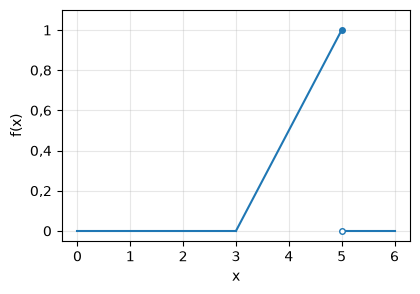

In [11]:
# Gráfico de f(x) = (x - 3)/2 para 3 <= x <= 5 (e zero fora desse intervalo)
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot([0, 3], [0, 0], color="tab:blue")
ax.plot([3, 5], [0, 1], color="tab:blue")
ax.plot([5, 6], [0, 0], color="tab:blue")
ax.plot(5, 1, "o", color="tab:blue", ms=4)
ax.plot(5, 0, "o", mfc="white", color="tab:blue", ms=4)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_ylim(-0.05, 1.1)
ax.grid(alpha=0.3)
virgula(ax)
plt.show()

In [78]:
#Definição da função e teste de um valor conhecido
def funcao(x):
    if x<=3 or x>=5:
        return 0
    else:
        return (x-3)/2
    
funcao(4.999)

0.9994999999999998

In [103]:
#Declaração manual de valores para a V.A. contínua e aplicação na função para visualização
X = [2, 3, 3.1, 3.5, 4, 4.5, 4.9, 5, 6]
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(2)=  0.0000
f(3)=  0.0000
f(3.1)=  0.0500
f(3.5)=  0.2500
f(4)=  0.5000
f(4.5)=  0.7500
f(4.9)=  0.9500
f(5)=  0.0000
f(6)=  0.0000


In [77]:
#Declaração automática de valores para a V.A. contínua e aplicação na função para visualização
import numpy as np
X = np.arange(2, 6, 0.5)
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(2.0)=  0.0000
f(2.5)=  0.0000
f(3.0)=  0.0000
f(3.5)=  0.2500
f(4.0)=  0.5000
f(4.5)=  0.7500
f(5.0)=  0.0000
f(5.5)=  0.0000


In [100]:
#Verifica se a função definida é positiva para todo x. 
#Obs: definir os limites e o passo do 'arange' para avaliar toda a função.
atende_cond_a = True
for k in np.arange(0, 6, 0.1):
    if funcao(k)>=0:
        next
    else:
        atende_cond_a = False

if atende_cond_a == True:
    print("f(x) atende a condição (a) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (a) para ser uma função densidade de probabilidade")

f(x) atende a condição (a) para ser uma função densidade de probabilidade


2º passo: Verificar se a área sob a curva da função f(x), em seu domínio, é igual a 1.
Por meio do cálculo da área da função f(x) temos que:

Uma primitiva de $f$ em $[3, 5]$ é $F(x) = \dfrac{x^2}{4} - \dfrac{3x}{2}$. Assim:

$$\int_{3}^{5} \frac{x - 3}{2} dx = F(5) - F(3) = \left(\frac{5^2}{4} - \frac{3 \cdot 5}{2}\right) - \left(\frac{3^2}{4} - \frac{3 \cdot 3}{2}\right) = (-1{,}25) - (-2{,}25) = 1$$

Dessa maneira podemos dizer que a função f(x) descrita no problema é uma função densidade de probabilidade (f.d.p.).

In [81]:
#Integral da função definida com os limites mínimo e máximo definidos
from scipy.integrate import quad
Integral = quad(funcao, 3, 5)
Integral[0]

1.0

In [84]:
#Integral da função definida com os limites infinitos
from scipy.integrate import quad
Integral = quad(funcao, -np.inf, np.inf)
Integral[0]

0.999999999999988

In [88]:
#Verifica se a Integral é aproximadamente 1 considerando o erro de cálculo da integral.
if abs(1-Integral[0]) <= Integral[1]:
    print("f(x) atende a condição (b) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (b) para ser uma função densidade de probabilidade")

f(x) atende a condição (b) para ser uma função densidade de probabilidade


- b) Se a função for uma fdp, calcule P(3,3<X<4).

Com a mesma primitiva $F(x) = \dfrac{x^2}{4} - \dfrac{3x}{2}$:

$$P(3{,}3 \le X < 4) = \int_{3{,}3}^{4} \frac{x - 3}{2} dx = F(4) - F(3{,}3) = \left(\frac{4^2}{4} - \frac{3 \cdot 4}{2}\right) - \left(\frac{3{,}3^2}{4} - \frac{3 \cdot 3{,}3}{2}\right) = (-2) - (-2{,}2275) = 0{,}2275$$

In [101]:
#Integral da função definida com os limites definidos
from scipy.integrate import quad
Integral = quad(funcao, 3.3, 4)
Integral[0]

0.22749999999999998

### Tendência central e variabilidade para V.A contínuas:

O valor esperado ou média da variável aleatória contínua X, com função densidade de probabilidade dada por f(x), é obtida pela expressão:

$$E(X) = \mu = \int_{-\infty}^{+\infty} x f(x) dx$$

Para uma variável aleatória X com densidade f(x), a variância é dada por:

$$\text{Var}(X) = \int_{-\infty}^{+\infty} (x - \mu)^2 f(x) dx$$

Como no caso discreto, a variância é a medida de dispersão mais utilizada na prática. Aqui podemos, também, utilizar a expressão alternativa:

$$\text{Var}(X) = E(X^2) - \mu^2$$

onde E(X²) é calculado por:

$$E(X^2) = \int_{-\infty}^{+\infty} x^2 f(x) dx$$

O desvio padrão é a raiz quadrada da variância e, como já sabemos, tem a mesma unidade de medida da variável original, o que facilita sua interpretação.

#### Exemplo:
Num teste educacional com crianças, o tempo para a realização de uma bateria de questões de raciocínio verbal e lógico é medido e anotado para ser comparado com um modelo teórico. Este teste é utilizado para identificar o desenvolvimento da crianças e auxiliar a aplicação de medidas corretivas. O modelo teórico considera T, tempo de teste em minutos, como uma variável aleatória contínua com função densidade de probabilidade dada por:

- $f(t) = \dfrac{t - 4}{40}$, se $8 \le t < 10$;
- $f(t) = \dfrac{3}{20}$, se $10 \le t \le 15$;
- $f(t) = 0$, caso contrário.

- a) Calcule o tempo médio do teste em minutos.

$$E(T) = \int_{8}^{10} t \cdot \frac{t - 4}{40} dt + \int_{10}^{15} t \cdot \frac{3}{20} dt$$

As primitivas são $\dfrac{t^3}{120} - \dfrac{t^2}{20}$ (primeira integral) e $\dfrac{3t^2}{40}$ (segunda). Avaliando nos limites:

$$E(T) = 2{,}2667 + 9{,}375 = 11{,}6417 \text{ minutos}$$

    - Verificando se a função é uma função densidade de probabilidade:

In [119]:
#Definição da função
def funcao(t):
    if t>=8 and t<10:
        return (t-4)/40
    elif t>=10 and t<=15:
        return 3/20
    else:
        return 0
    
funcao(14.99)

0.15

In [120]:
#Declaração automática de valores para a V.A. contínua e aplicação na função para visualização
import numpy as np
X = np.arange(7, 16, 0.5)
for k in X:
    print("f({0})={1:8.4f}" .format(k,funcao(k)))

f(7.0)=  0.0000
f(7.5)=  0.0000
f(8.0)=  0.1000
f(8.5)=  0.1125
f(9.0)=  0.1250
f(9.5)=  0.1375
f(10.0)=  0.1500
f(10.5)=  0.1500
f(11.0)=  0.1500
f(11.5)=  0.1500
f(12.0)=  0.1500
f(12.5)=  0.1500
f(13.0)=  0.1500
f(13.5)=  0.1500
f(14.0)=  0.1500
f(14.5)=  0.1500
f(15.0)=  0.1500
f(15.5)=  0.0000


In [121]:
#Verifica se a função definida é positiva para todo x. 
#Obs: definir os limites e o passo do 'arange' para avaliar toda a função!
atende_cond_a = True
for k in np.arange(7, 16, 0.1):
    if funcao(k)>=0:
        next
    else:
        atende_cond_a = False

if atende_cond_a == True:
    print("f(x) atende a condição (a) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (a) para ser uma função densidade de probabilidade")

f(x) atende a condição (a) para ser uma função densidade de probabilidade


In [151]:
#Integral da função definida com os limites infinitos
from scipy.integrate import quad
Integral = quad(funcao, -np.inf, np.inf)
Integral[0]

1.0000000001427456

In [123]:
#Verifica se a Integral é aproximadamente 1 considerando o erro de cálculo da integral.
if abs(1-Integral[0]) <= Integral[1]:
    print("f(x) atende a condição (b) para ser uma função densidade de probabilidade")
else:
    print("f(x) não atende a condição (b) para ser uma função densidade de probabilidade")
    print(Integral)
    print(1-Integral[0])

f(x) atende a condição (b) para ser uma função densidade de probabilidade


    - Definindo o integrando como x.f(x) para cálculo da média

In [134]:
#Integral de xf(x) calculando a média parcial do limite 'a' até 'b'
def integrando(t):
    return t*funcao(t)

a=8
b=10

from scipy.integrate import quad
Integral_parcial_1 = quad(integrando, a, b)
Integral_parcial_1[0]

2.2666666666666666

In [132]:
#Integral de xf(x) dx calculando a média parcial do limite 'a' até 'b'
def integrando(t):
    return t*funcao(t)

a=10
b=15

from scipy.integrate import quad
Integral_parcial_2 = quad(integrando, a, b)
Integral_parcial_2[0]

9.375000000000002

In [141]:
#Cálculo da média através da soma das médias parciais.
Media_Pc = Integral_parcial_1[0] + Integral_parcial_2[0]
Media_Pc

11.64166666666667

- b) Calcule o desvio padrão do tempo de teste em minutos.

Primeiramente vamos calcular o E(T²):

$$E(T^2) = \int_{8}^{10} t^2 \cdot \frac{t - 4}{40} dt + \int_{10}^{15} t^2 \cdot \frac{3}{20} dt$$

As primitivas são $\dfrac{t^4}{160} - \dfrac{t^3}{30}$ e $\dfrac{t^3}{20}$. Avaliando nos limites:

$$E(T^2) = 20{,}6333 + 118{,}75 = 139{,}3833$$

In [139]:
#Integral de x²f(x) dx calculando a média parcial ao quadrado do limite 'a' até 'b'
def integrando_2(t):
    return (t**2)*funcao(t)

a=8
b=10

from scipy.integrate import quad
Integral_parcial_2_1 = quad(integrando_2, a, b)
Integral_parcial_2_1[0]

20.633333333333333

In [138]:
#Integral de x²f(x) dx calculando a média parcial ao quadrado do limite 'a' até 'b'
def integrando_2(t):
    return (t**2)*funcao(t)

a=10
b=15

from scipy.integrate import quad
Integral_parcial_2_2 = quad(integrando_2, a, b)
Integral_parcial_2_2[0]

118.75

In [142]:
#Cálculo da média ao quadrado através da soma das médias parciais ao quadrado.
Media_Pc_2 = Integral_parcial_2_1[0] + Integral_parcial_2_2[0]
Media_Pc_2

139.38333333333333

Agora calcularemos a variância de T:

$$\text{Var}(T) = E(T^2) - \mu^2 = \frac{8363}{60} - \left(\frac{1397}{120}\right)^2 = \frac{55511}{14400} \approx 3{,}8549$$

(As frações são os valores exatos de $E(T^2) \approx 139{,}3833$ e $\mu \approx 11{,}6417$; arredondar $\mu$ antes de elevar ao quadrado muda a última casa decimal.)

In [143]:
Variancia_Pc = Media_Pc_2 - (Media_Pc**2)
Variancia_Pc

3.854930555555484

Por fim, calculamos o desvio padrão:

$$\sigma = \sqrt{\text{Var}(T)} = \sqrt{3{,}8549} \approx 1{,}9634 \text{ minuto}$$

In [145]:
Desvio_P_Pc = Variancia_Pc**0.5
Desvio_P_Pc

1.9633977069242705

- c) Calcule a probabilidade de uma criança gastar entre 9 e 12 minutos na realização do teste.

$$P(9 < T < 12) = \int_{9}^{10} \frac{t - 4}{40} dt + \int_{10}^{12} \frac{3}{20} dt = 0{,}1375 + 0{,}3 = 0{,}4375$$

In [148]:
#Integral diretamente da função definida com os limites de acordo com enunciado.
from scipy.integrate import quad
Integral_1 = quad(funcao, 9, 12)
Integral_1[0]

0.43749999999999994

- d) Sabendo-se que a criança demorou mais de 8 minutos na realização do teste, qual a probabilidade de que tenha gastado menos de 14 minutos. Aqui iremos trabalhar com uma probabilidade condicional aplicada a uma variável aleatória contínua:

$$P(T < 14 \mid T > 8) = \frac{P(T < 14 \text{ e } T > 8)}{P(T > 8)} = \frac{P(8 < T < 14)}{P(T > 8)}$$

$$P(T < 14 \mid T > 8) = \frac{\int_{8}^{10} \frac{t - 4}{40} dt + \int_{10}^{14} \frac{3}{20} dt}{\int_{8}^{10} \frac{t - 4}{40} dt + \int_{10}^{15} \frac{3}{20} dt} = \frac{0{,}25 + 0{,}6}{0{,}25 + 0{,}75} = 0{,}85$$

In [149]:
#Integral diretamente da função definida com os limites de acordo com enunciado.
from scipy.integrate import quad
Integral_2_1 = quad(funcao, 8, 14)
Integral_2_2 = quad(funcao, 8, np.inf)
Integral_2 = Integral_2_1[0] / Integral_2_2[0]
Integral_2

0.8499999999999966

## Modelos probabilísticos para V.A. discretas

Os tipos de distribuição de probabilidade mais comuns para o caso em que X é uma variável aleatória discreta são:
- a) Uniforme discreta
- b) Bernoulli
- c) Geométrica
- d) Pascal ou Binomial negativa
- e) Hipergeométrica
- f) Polinomial ou multinomial
- g) Binomial
- h) Poisson

### Distribuição Binomial

Considere um experimento aleatório consistindo em n tentativas independentes e a probabilidade de ocorrer sucesso em cada uma das n tentativas é sempre igual a p e de fracasso é q, onde p + q = 1. A probabilidade de sucesso e fracasso são as mesmas para cada tentativa.

Definição: Seja X o número de sucesso em n tentativas, então X pode assumir os valores 0, 1, 2,..., n. Nesta condição a v.a. X tem distribuição Binomial com parâmetro n e p, isto é, X ~ B(n; p).
Considere que se X ~ B(n; p), então a média e a variância de X são definidos
por:
- a) Média de X: E(X) = np.
- b) Variância de X: σ² = npq, onde q = 1 - p.

A função de probabilidade da variável aleatória X ~ B(n; p) é dada por:

$$P(X = x) = \binom{n}{x} p^x (1 - p)^{n - x}, \quad x = 0, 1, 2, \ldots, n$$

Onde a combinação de n, x a x, representa o coeficiente binominal calculado:

$$\binom{n}{x} = \frac{n!}{x! \cdot (n - x)!}$$

#### Exemplo:

Suponha que 5% de todas as peças que saiam de uma linha de produção sejam defeituosas. Se 10 dessas peças forem escolhidas e inspecionadas, pede-se:

Observe que temos:
- Um experimento com somente duas opções de resposta (peças defeituosas ou não defeituosas);
- Um número fixo e independente de vezes que o experimento será repetido (10 amostras);
- A probabilidade de peças defeituosas é constante p=0,05 e, consequentemente, a probabilidade de peças não defeituosas q=1- p=0,95.

Dessa forma, podemos dizer que o modelo binomial se adapta bem à situação proposta no exemplo, ou seja, X ~ B(10; 0,05),

- a) Identifique a variável aleatória estudada. Quais valores ela pode assumir?

    X: número de peças defeituosas produzidas;
    
    x= 0, 1, 2,..., 10.

- b) Calcule o número médio de peças defeituosas e, também, o desvio padrão.

    Média: E(X) = np = 10 . 0,05 = 0,5;
    
    Variância: σ² = npq = 10 . 0,05 . 0,95 = 0,475;
    
    Desvio padrão: σ = √𝜎² = 0,6892.

In [153]:
#Definindo n e p
n = 10
p = 0.05
q = 1 - p
q

0.95

In [159]:
#Calculando a Média de X ~ B(n;p)
Media_B = n*p
print("Média (E(X)) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Media_B))

Média (E(X)) de X~B(10;0.05) =   0.5000


In [158]:
#Calculando Variância e Desvio Padrão de X ~ B(n;p)
Variancia_B = n*p*q
print("Variância (σ²) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Variancia_B))
Desvio_P_B = Variancia_B**0.5
print("Desvio padrão (σ) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Desvio_P_B))

Variância (σ²) de X~B(10;0.05) =   0.4750
Desvio padrão (σ) de X~B(10;0.05) =   0.6892


- b) Qual será a probabilidade de que:
        Exatamente 7 sejam defeituosas?

$$P(X = 7) = \binom{10}{7} \cdot 0{,}05^7 \cdot 0{,}95^3 = 120 \cdot 0{,}05^7 \cdot 0{,}95^3 \approx 8{,}0379 \times 10^{-8}$$

In [161]:
#Calculando coeficiente binominal para x de acordo com enunciado:
from math import factorial

x = 7

Coeficiente_B = factorial(n) / (factorial(x) * factorial(n-x))
Coeficiente_B

120.0

In [162]:
#Calculando a Probabilidade de acordo com a fómula da Distribuição Binominal
Prob_B = Coeficiente_B * (p**x) * (q**(n-x))
Prob_B

8.037890625000001e-08

- b) Qual será a probabilidade de que:
        No máximo 8 sejam defeituosas?

$$P(X \le 8) = 1 - P(X > 8) = 1 - [P(X = 9) + P(X = 10)]$$

$$P(X = 9) = \binom{10}{9} \cdot 0{,}05^9 \cdot 0{,}95^1 \approx 1{,}8555 \times 10^{-11}$$

$$P(X = 10) = \binom{10}{10} \cdot 0{,}05^{10} \cdot 0{,}95^0 \approx 9{,}7656 \times 10^{-14}$$

$$P(X \le 8) \approx 1 - 1{,}8652 \times 10^{-11} \approx 1$$

    Calculando através do inverso de Probabilidade, conforme resposta acima:

In [169]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

# P(X <= 8) = 1 - P(X > 8)
# X = [0, 1, 2,...,10]
# P(X > 8) = P(X = 9) + P(X = 10), portanto,
x = [9, 10]

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

Coenficiente (X = 9) = 10.0
Coenficiente (X = 10) = 1.0


In [173]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_B))

P(X = 9) = 1.8554687500000008e-11
P(X = 10) = 9.765625000000005e-14


A soma das probabilidade é: 1.865234375000001e-11
O inverso da soma das probabilidade é: 0.9999999999813477


    Calculando diretamente a Probabilidade socilitada como é mais intuitivo:

In [177]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

# P(X <= 8)
# portanto,
x = np.arange(0, 9 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2 3 4 5 6 7 8]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 10.0
Coenficiente (X = 2) = 45.0
Coenficiente (X = 3) = 120.0
Coenficiente (X = 4) = 210.0
Coenficiente (X = 5) = 252.0
Coenficiente (X = 6) = 210.0
Coenficiente (X = 7) = 120.0
Coenficiente (X = 8) = 45.0


In [178]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.5987369392383787
P(X = 1) = 0.31512470486230454
P(X = 2) = 0.07463479852001952
P(X = 3) = 0.010475059441406248
P(X = 4) = 0.0009648081064453125
P(X = 5) = 6.0935248828124994e-05
P(X = 6) = 2.672598632812501e-06
P(X = 7) = 8.037890625000001e-08
P(X = 8) = 1.586425781250001e-09


A soma das probabilidade é: 0.9999999999813473


- b) Qual será a probabilidade de que:
        Mais de 7 não sejam defeituosas?



Como cada amostra tem 10 peças, "mais de 7 não defeituosas" (8, 9 ou 10) é o mesmo evento que "menos de 3 defeituosas" (2, 1 ou 0):

| Peças não defeituosas | Peças defeituosas |
|---|---|
| 8 | 2 |
| 9 | 1 |
| 10 | 0 |

Dessa forma, para obter a probabilidade de mais de 7 peças não defeituosas deveríamos calcular a probabilidade de menos de três peças defeituosas na amostra:

$$P(X < 3) = P(X \le 2) = P(X = 0) + P(X = 1) + P(X = 2) \approx 0{,}59874 + 0{,}31512 + 0{,}07463 \approx 0{,}9885$$

In [179]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo n e p
n = 10
p = 0.05
q = 1 - p

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 2) portanto,
x = np.arange(0, 3 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 10.0
Coenficiente (X = 2) = 45.0


In [180]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.5987369392383787
P(X = 1) = 0.31512470486230454
P(X = 2) = 0.07463479852001952


A soma das probabilidade é: 0.9884964426207028


#### Exercício 1:

Cada amostra de ar tem 10% de chance de conter uma certa molécula rara. Considere que as amostras sejam independentes com relação à presença da molécula rara. Encontre a probabilidade de que nas próximas 18 amostras:

- a) Exatamente 2 contenham a molécula rara. R: 0,2835

In [182]:
#Definindo n e p
n = 18
p = 0.1
q = 1 - p
q

0.9

In [183]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 2) portanto,
x = [2]

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [2]
Coenficiente (X = 2) = 153.0


In [184]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 2) = 0.2835120888943318


A soma das probabilidade é: 0.2835120888943318


- b) No mínimo 4 amostras contenham a molécula rara. R: 0,0982

In [185]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 4) portanto,
x = np.arange(4, 19 , 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18]
Coenficiente (X = 4) = 3060.0
Coenficiente (X = 5) = 8568.0
Coenficiente (X = 6) = 18564.0
Coenficiente (X = 7) = 31824.0
Coenficiente (X = 8) = 43758.0
Coenficiente (X = 9) = 48620.0
Coenficiente (X = 10) = 43758.0
Coenficiente (X = 11) = 31824.0
Coenficiente (X = 12) = 18564.0
Coenficiente (X = 13) = 8568.0
Coenficiente (X = 14) = 3060.0
Coenficiente (X = 15) = 816.0
Coenficiente (X = 16) = 153.0
Coenficiente (X = 17) = 18.0
Coenficiente (X = 18) = 1.0


In [186]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 4) = 0.0700029849121807
P(X = 5) = 0.021778706417122883
P(X = 6) = 0.005243021915233288
P(X = 7) = 0.0009986708409968166
P(X = 8) = 0.00015257471181895813
P(X = 9) = 1.8836384175180014e-05
P(X = 10) = 1.8836384175180015e-06
P(X = 11) = 1.5221320545600012e-07
P(X = 12) = 9.865670724000007e-09
P(X = 13) = 5.059318320000004e-10
P(X = 14) = 2.0076660000000014e-11
P(X = 15) = 5.948640000000005e-13
P(X = 16) = 1.2393000000000012e-14
P(X = 17) = 1.6200000000000017e-16
P(X = 18) = 1.000000000000001e-18


A soma das probabilidade é: 0.09819684142543746


- c) De 3 a 7 amostras contenham a molécula rara. R: 0,2660

In [187]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 3) - P(X > 7) portanto,
x = np.arange(3, 8, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [3 4 5 6 7]
Coenficiente (X = 3) = 816.0
Coenficiente (X = 4) = 3060.0
Coenficiente (X = 5) = 8568.0
Coenficiente (X = 6) = 18564.0
Coenficiente (X = 7) = 31824.0


In [188]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 3) = 0.16800716378923367
P(X = 4) = 0.0700029849121807
P(X = 5) = 0.021778706417122883
P(X = 6) = 0.005243021915233288
P(X = 7) = 0.0009986708409968166


A soma das probabilidade é: 0.2660305478747673


- d) O número médio e a variância de moléculas raras. R: 1,8 e 1,62.

In [189]:
#Definindo n e p
n = 18
p = 0.1
q = 1 - p
q

0.9

In [190]:
#Calculando a Média de X ~ B(n;p)
Media_B = n*p
print("Média (E(X)) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Media_B))

Média (E(X)) de X~B(18;0.1) =   1.8000


In [191]:
#Calculando Variância e Desvio Padrão de X ~ B(n;p)
Variancia_B = n*p*q
print("Variância (σ²) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Variancia_B))
Desvio_P_B = Variancia_B**0.5
print("Desvio padrão (σ) de X~B({0};{1}) = {2:8.4f}" .format(n,p,Desvio_P_B))

Variância (σ²) de X~B(18;0.1) =   1.6200
Desvio padrão (σ) de X~B(18;0.1) =   1.2728


#### Exercício 2:

Se 20% dos parafusos produzidos por uma maquina são defeituosos, determine qual a probabilidade de, entre 4 parafusos selecionados ao acaso, no máximo 2 deles serem defeituosos. Resposta:0,9728

In [192]:
#Definindo n e p
n = 4
p = 0.2
q = 1 - p
q

0.8

In [193]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 2) portanto,
x = np.arange(0, 3, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [0 1 2]
Coenficiente (X = 0) = 1.0
Coenficiente (X = 1) = 4.0
Coenficiente (X = 2) = 6.0


In [194]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 0) = 0.4096000000000001
P(X = 1) = 0.40960000000000013
P(X = 2) = 0.15360000000000007


A soma das probabilidade é: 0.9728000000000002


#### Exercício 3:

Um fabricante de certas peças de automóveis garante que uma caixa de suas peças conterá no máximo 2 itens defeituosos. Se a caixa contem 20 peças e a experiência tem demonstrado que esse processo de fabricação produz 2 por cento de itens defeituosos, qual a probabilidade de que uma caixa de suas peças não vá satisfazer a garantia?
Resposta: 0,0071

In [195]:
#Definindo n e p
n = 20
p = 0.02
q = 1 - p
q

0.98

In [200]:
#Calculando os coeficientes binominais para mais de um x de acordo com enunciado:
from math import factorial
import numpy as np

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X > 2) portanto,
x = np.arange(3, 21, 1)

print("X pode assumir os valores:", x)

Coeficiente_B = np.zeros(len(x))
for i,j in enumerate(x):
    Coeficiente_B[i] = factorial(n) / (factorial(j) * factorial(n-j))
    print("Coenficiente (X = {0}) = {1}" .format(j,Coeficiente_B[i]))

X pode assumir os valores: [ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Coenficiente (X = 3) = 1140.0
Coenficiente (X = 4) = 4845.0
Coenficiente (X = 5) = 15504.0
Coenficiente (X = 6) = 38760.0
Coenficiente (X = 7) = 77520.0
Coenficiente (X = 8) = 125970.0
Coenficiente (X = 9) = 167960.0
Coenficiente (X = 10) = 184756.0
Coenficiente (X = 11) = 167960.0
Coenficiente (X = 12) = 125970.0
Coenficiente (X = 13) = 77520.0
Coenficiente (X = 14) = 38760.0
Coenficiente (X = 15) = 15504.0
Coenficiente (X = 16) = 4845.0
Coenficiente (X = 17) = 1140.0
Coenficiente (X = 18) = 190.0
Coenficiente (X = 19) = 20.0
Coenficiente (X = 20) = 1.0


In [201]:
#Calculando a soma de todas as Probabilidades de acordo com a fómula da Distribuição Binominal
Prob_B = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_B[i] = Coeficiente_B[i] * (p**j) * (q**(n-j))
    print("P(X = {0}) = {1}" .format(j,Prob_B[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_B))

P(X = 3) = 0.006469014507567489
P(X = 4) = 0.0005610879930033026
P(X = 5) = 3.664248117572589e-05
P(X = 6) = 1.8695143457003005e-06
P(X = 7) = 7.630670798776736e-08
P(X = 8) = 2.5305796016351426e-09
P(X = 9) = 6.88593088880311e-11
P(X = 10) = 1.5458212199353919e-12
P(X = 11) = 2.8679428941287423e-14
P(X = 12) = 4.389708511421544e-16
P(X = 13) = 5.512977722350449e-18
P(X = 14) = 5.625487471786173e-20
P(X = 15) = 4.592234670845855e-22
P(X = 16) = 2.9287210911006724e-24
P(X = 17) = 1.4063486631936003e-26
P(X = 18) = 4.783498854400002e-29
P(X = 19) = 1.0276044800000003e-31
P(X = 20) = 1.0485760000000004e-34


A soma das probabilidade é: 0.007068693403814062


### Distribuição Poisson (distribuição dos eventos raros)

Consideremos as seguintes variáveis aleatórias:

    X1 = Número de chamadas recebidas por uma central telefônica durante um período de 30 minutos;
    X2 = Número de bactérias em um litro de água não-purificada;
    X3 = Número de partículas radiativas que, em um experimento de laboratório, entram em um contador durante um milissegundo;
    X4 = Número de acidentes com automóveis particulares em determinado trecho de estrada, no período de 12 horas.

Note-se que em todos esses exemplos a variável aleatória (X) consiste na contagem de eventos discretos que ocorrem em um meio contínuo (tempo, volume, área, etc.). Essas variáveis tomam os valores x= 0, 1, 2, ..., e seu comportamento pode ser descrito pela chamada distribuição de Poisson cuja função de probabilidade é:

$$P(X = x) = \frac{e^{-\lambda} \lambda^x}{x!}, \quad x = 0, 1, 2, \ldots$$

Onde λ > 0 é o parâmetro da distribuição, sendo referido como a taxa de ocorrência, ou seja, o número médio de eventos ocorrendo no intervalo considerado. Utiliza-se a notação: X ~ Po(λ).

Se X tiver distribuição de Poisson com parâmetro λ, então o valor esperado e a variância são:

$$E(X) = \lambda \qquad \text{Var}(X) = \lambda$$

#### Exemplo:
Uma central telefônica recebe, em média, cinco chamadas por minuto.
- a) Defina a variável aleatória.

        X: Número de chamadas recebidas por minuto.
        x: 0, 1, 2, ...
        X ~ Po(5)

- b) Calcule a probabilidade de que durante um intervalo de um minuto:

    i. A central telefônica não receba chamada.

$$P(X = 0) = \frac{e^{-5} \cdot 5^0}{0!} \approx 0{,}0067$$

In [203]:
#Definindo a Média/Taxa de ocorrência do evento.
Media_Po = 5

In [205]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0 ) portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))


X pode assumir os valores: [0]
P(X = 0) = 0.006737946999085467


A soma das probabilidade é: 0.006737946999085467


- b) Calcule a probabilidade de que durante um intervalo de um minuto:

    ii. Receba, no máximo, uma chamada.

$$P(X = 1) = \frac{e^{-5} \cdot 5^1}{1!} \approx 0{,}0337$$

$$P(X \le 1) = P(X = 0) + P(X = 1) \approx 0{,}0067 + 0{,}0337 = 0{,}0404$$

In [206]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X <= 1) portanto,
x = [0, 1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))


X pode assumir os valores: [0, 1]
P(X = 0) = 0.006737946999085467
P(X = 1) = 0.03368973499542734


A soma das probabilidade é: 0.040427681994512805


- b) Calcule a probabilidade de que durante um intervalo de um minuto:

    iii. Receba mais de duas chamadas.

$$P(X = 2) = \frac{e^{-5} \cdot 5^2}{2!} \approx 0{,}0842$$

$$P(X > 2) = 1 - P(X \le 2) = 1 - [P(X = 0) + P(X = 1) + P(X = 2)] \approx 1 - 0{,}1247 = 0{,}8753$$

In [207]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X > 2) porém cálculo com infinito complica,
# então,
# P(X > 2) = 1 - P(X <= 2) = 1 - [P(X=0) -  P(X=1) - P(X=2)]
x = np.arange(0, 3, 1)

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0 1 2]
P(X = 0) = 0.006737946999085467
P(X = 1) = 0.03368973499542734
P(X = 2) = 0.08422433748856833


A soma das probabilidade é: 0.12465201948308113
O inverso da soma das probabilidade é: 0.8753479805169189


- c) Durante um intervalo de quatro minutos, qual a probabilidade de que ocorram 15 chamadas?

Nesse caso, como o intervalo de tempo foi alterado, o parâmetro da distribuição também irá sofrer alteração proporcional, ou seja, λ= 5 chamadas por minuto passará a ser λ= 20 chamadas por quatro minutos. Assim:

$$P(X = 15) = \frac{e^{-20} \cdot 20^{15}}{15!} \approx 0{,}0516$$

In [209]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o período de tempo do enunciado.
Tempo = 4 #minutos
Media_Po = 5*Tempo

In [210]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 15) portanto,
x = [15]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [15]
P(X = 15) = 0.05164885353175835


A soma das probabilidade é: 0.05164885353175835


#### Exercício 4:
Falhas ocorrem, ao acaso, ao longo do comprimento de um fio delgado de cobre. Suponha que o número de falhas siga a distribuição de Poisson, com uma média de 2,3 falhas por milímetro.

- a) Determine a probabilidade de existir exatamente 2 falhas em 1 milímetro de fio. R: 0,2652

In [213]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #milimetros
Media_Po = 2.3*Comprimento

In [214]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 15) portanto,
x = [2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [2]
P(X = 2) = 0.2651846416468159


A soma das probabilidade é: 0.2651846416468159


- b) Determine a probabilidade de existir entre 2 e 4 falhas em 1 milímetro de fio. R: 0,2033

    Para variáveis aleatórias discretas, ou seja, que assumem somente valores inteiros, temos que ter muito cuidado visto que: A Probabilidade de 2 a 4 ocorrências corresponde a P(2<=X<=4) = P(X=2)+P(X=3)+P(X=4) porém, a probabilidade entre 2 e 4 ocorrências corresponde a P(2<X<4)=P(X=3). Em nosso dia-a-dia, temos o costume de dizer 'de 2 a 4' e 'entre 2 e 4' como sinônimos mas, matematicamente falando, são diferentes. Para variáveis aleatórias contínuas, pela maneira como as probabilidades são obtidas (por meio do cálculo da área), aí sim P(2<=X<=4) = P(2<X<4).

In [213]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #milimetros
Media_Po = 2.3*Comprimento

In [218]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# Pelo termo 'entre 2 e 4' não incluir os extremos, P(X = 3), portanto,
x = [3]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [3]
P(X = 3) = 0.20330822526255884


A soma das probabilidade é: 0.20330822526255884


- c) Determine a probabilidade de 10 falhas em 5 milímetros de fio. R: 0,1129

In [220]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 5 #milimetros
Media_Po = 2.3*Comprimento

In [221]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 10) portanto,
x = [10]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [10]
P(X = 10) = 0.11293507088124353


A soma das probabilidade é: 0.11293507088124353


- d) Determine a probabilidade de existir, no mínimo, uma falha em 2 milímetros de fio. R: 0,99

In [222]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 2 #milimetros
Media_Po = 2.3*Comprimento

In [223]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 1) e por ter infinito, usando o inverso,
# P(X >= 1)  = 1 - P(X < 1) = 1 - P(X=0), portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.010051835744633586


A soma das probabilidade é: 0.010051835744633586
O inverso da soma das probabilidade é: 0.9899481642553665


#### Exercício 5:
O número de falhas em parafusos de máquinas da indústria textil segue distribuição de Poisson, com uma média de 0,1 falha por metro quadrado.

- a) Qual é a probabilidade de que haja duas falhas em 1 metro quadrado de tecido? R: 0,0045

In [225]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 1 #metro²
Media_Po = 0.1*Comprimento

In [226]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 2) portanto,
x = [2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [2]
P(X = 2) = 0.004524187090179798


A soma das probabilidade é: 0.004524187090179798


- b) Qual é a probabilidade de que haja uma falha em 10 metros quadrados de tecido? R: 0,3679

In [228]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 10 #metro²
Media_Po = 0.1*Comprimento

In [229]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 1) portanto,
x = [1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [1]
P(X = 1) = 0.36787944117144233


A soma das probabilidade é: 0.36787944117144233


- c) Qual é a probabilidade de que não haja falhas em 20 metros quadrados de tecido? R: 0,1353

In [231]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 20 #metro²
Media_Po = 0.1*Comprimento

In [232]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0) portanto,
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))

print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.1353352832366127


A soma das probabilidade é: 0.1353352832366127


- d) Qual é a probabilidade de que haja no mínimo duas falhas em 10 metros quadrados de tecido? R: 0,2642

In [238]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Comprimento = 10 #metro²
Media_Po = 0.1*Comprimento

In [249]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 2) e por envolver infinito, usando o inverso,
# P(X >= 2) = 1 - P(X < 2) = 1 - [P(X=0) + P(X=1)]
x = [0, 1]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0, 1]
P(X = 0) = 0.36787944117144233
P(X = 1) = 0.36787944117144233


A soma das probabilidade é: 0.7357588823428847
O inverso da soma das probabilidade é: 0.26424111765711533


#### Exercício 6:
Um engenheiro de tráfego monitora o fluxo de carros em um cruzamento que tem uma média de 6 carros por minuto. Para estabelecer o tempo de um sinal, as seguintes probabilidade são utilizadas:

- a) Qual é a probabilidade de nenhum carro passar pelo cruzamento em 30 segundos? R: 0,0498

In [250]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Tempo = 0.5 #minuto
Media_Po = 6*Tempo

In [251]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X = 0)
x = [0]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))

X pode assumir os valores: [0]
P(X = 0) = 0.049787068367863944


A soma das probabilidade é: 0.049787068367863944


- b) Qual é a probabilidade de três ou mais carros passarem pelo cruzamento em 30 segundos? R: 0,5768

In [250]:
#Definindo a Média/Taxa de ocorrência do evento de acordo com o comprimento do enunciado.
Tempo = 0.5 #minuto
Media_Po = 6*Tempo

In [252]:
#Calculando a Probabilidade de acordo com a fórmula da Distribuição de Poisson
from math import factorial, exp

#Definindo quais valores x estão sendo estudados as probabilidades:
# P(X >= 3) e por envolver infinito, usando o inverso,
# P(X >= 3) = 1 - P(X < 3) = 1 - [P(X=0) + P(X=1) + P(X=2)]
x = [0, 1, 2]

print("X pode assumir os valores:", x)

Prob_Po = np.zeros(len(x))
for i,j in enumerate(x):
    Prob_Po[i] = (exp(-Media_Po) * (Media_Po**j)) / factorial(j)
    print("P(X = {0}) = {1}" .format(j,Prob_Po[i]))
    
print("\n")
print("A soma das probabilidade é:", sum(Prob_Po))
print("O inverso da soma das probabilidade é:", 1-sum(Prob_Po))

X pode assumir os valores: [0, 1, 2]
P(X = 0) = 0.049787068367863944
P(X = 1) = 0.14936120510359183
P(X = 2) = 0.22404180765538775


A soma das probabilidade é: 0.42319008112684353
O inverso da soma das probabilidade é: 0.5768099188731565


## Modelos probabilísticos para V.A. contínuas

Os principais modelos de probabilidades que são designados para descreverem o comportamento de uma variável aleatória contínua são:
- a) Uniforme
- b) Normal
- c) Exponencial
- d) Gama
- e) Weibull
- f) Beta
- g) Lognormal

### Distribuição Exponencial

A distribuição exponencial é o modelo probabilístico usual para situações tais como tempo de espera em uma fila, tempo de sobrevivência de um paciente após o início de um tratamento, tempo de vida de material eletrônico. Definição: Uma v. a. X tem distribuição exponencial se sua função de densidade de probabilidade (f.d.p.) é da forma:

$$f(x) = \alpha e^{-\alpha x}, \quad x > 0 \text{ e } \alpha > 0$$

e $f(x) = 0$ para os demais valores de $x$.

A notação que utilizaremos para representar que uma v. a. contínua X tem distribuição exponencial é: X ~ Exp (α).

A média e a variância da distribuição exponencial são:

$$E(X) = \frac{1}{\alpha} \qquad \text{Var}(X) = \frac{1}{\alpha^2}$$

Apresentamos na figura abaixo o gráfico da distribuição exponencial para três valores diferentes para o parâmetro (α).

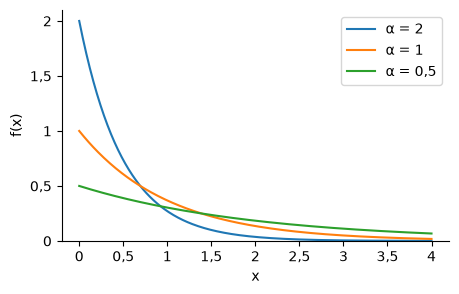

In [12]:
# Densidade exponencial f(x) = α·e^(-αx) para três valores de α
x_graf = np.linspace(0, 4, 300)
fig, ax = plt.subplots(figsize=(5, 3))
for alfa_graf in (2, 1, 0.5):
    ax.plot(x_graf, alfa_graf * np.exp(-alfa_graf * x_graf), label=f"α = {alfa_graf:g}".replace(".", ","))
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

Para uma variável aleatória contínua X distribuída exponencialmente, para qualquer intervalo de 'a' até 'b', a probabilidade P(a <= X <= b) é calculada por:

$$P(a \le X \le b) = \int_{a}^{b} \alpha e^{-\alpha x} dx = e^{-\alpha a} - e^{-\alpha b}$$

Lembre-se de que a inclusão ou não dos extremos a e b não altera o cálculo efetuado acima.

Para fins de simplificação, quando o limite inferior é igual a zero (a = 0), pode-se considerar a seguinte fórmula:

$$P(X > t) = e^{-\alpha t}$$

E no caso de utilização da probabilidade complementar:

$$P(X \le t) = 1 - e^{-\alpha t}$$

#### Propriedade de falta de memória: 
Considere uma variável aleatória contínua X com distribuição exponencial e parâmetro α. Considere também s e t > 0, então
temos que:

$$P(X \ge t + s \mid X \ge s) = \frac{P(X \ge t + s \text{ e } X \ge s)}{P(X \ge s)} = \frac{P(X \ge t + s)}{P(X \ge s)}$$

Como $P(X \ge u) = \int_{u}^{+\infty} \alpha e^{-\alpha x} dx = e^{-\alpha u}$ para qualquer $u > 0$:

$$P(X \ge t + s \mid X \ge s) = \frac{e^{-\alpha (t + s)}}{e^{-\alpha s}} = e^{-\alpha t} = P(X \ge t)$$

Supondo que X representa o tempo de vida de um equipamento, podemos fazer a seguinte interpretação para a propriedade da falta de memória: a probabilidade do equipamento durar pelo menos t+s anos, sabendo-se que já está funcionando a pelo menos s, é igual a probabilidade de um equipamento novo durar pelo menos t anos. Em outras palavras, a informação da “idade” do equipamento pode ser esquecida e o que importa, para o cálculo da probabilidade, é quantos anos a mais queremos que dure.

#### Exemplo 1:
A vida útil de uma lâmpada é modelada através da distribuição exponencial com parâmetro 1/8000.

- a) Calcule o tempo médio de duração dessas lâmpadas.

    X: vida útil de uma lâmpada;
    X ~ Exp (1/8000).

$$E(X) = \frac{1}{\alpha} = \frac{1}{1/8000} = 8000 \text{ horas}$$

In [253]:
#Definindo o parâmentro alfa (α) e calculando a Média.
Alfa_Exp = 1/8000
Media_Exp = 1/Alfa_Exp
Media_Exp

8000.0

- b) Calcule a probabilidade de que uma lâmpada dure pelo menos 4000 horas.

    Como a distribuição exponencial não tem um limite superior mas, tem o zero como limite inferior, para realizar o cálculo de que a lâmpada dure pelo menos 4000 horas iremos utilizar o complementar, ou seja,

$$P(X \ge 4000) = 1 - P(0 < X < 4000) = 1 - \left(e^{-0/8000} - e^{-4000/8000}\right) = e^{-0{,}5} \approx 0{,}6065$$

In [254]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Alfa_Exp = 1/8000


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado

# P(X >= 4000), por envolver infinito, usando o complementar da probabilidade,
# P(X >= 4000) = 1 - P(0 < X < 4000), portanto
a_Exp = 0
b_Exp = 4000


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.3934693402873666
O inverso da probabilidade é: 0.6065306597126334


- c) Sabe-se que o fabricante garante a reposição de uma lâmpada caso ela dure menos de 50 horas. Determine a probabilidade de haver troca por defeito na fabricação.

$$P(X < 50) = P(0 < X < 50) = e^{-0/8000} - e^{-50/8000} = 1 - e^{-0{,}00625} \approx 0{,}0062$$

In [255]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Alfa_Exp = 1/8000


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X < 50) = P(0 < X < 50), portanto
a_Exp = 0
b_Exp = 50


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.006230509376605298
O inverso da probabilidade é: 0.9937694906233947


- d) Uma lâmpada é colocada em teste. Calcule a probabilidade de que ela dure pelo menos 10000 horas, sabendo-se que ela já está em funcionamento a pelo menos 6000 horas. Para resolver essa probabilidade condicional podemos utilizar a propriedade de falta de memória da distribuição exponencial:

$$P(X \ge 10000 \mid X \ge 6000) = P(X \ge 4000) \approx 0{,}6065$$

In [257]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α), tempo estimado de duração (t+s) e tempo de uso (s)
Alfa_Exp = 1/8000
s_Exp = 6000
t_Exp = 10000 - s_Exp

#Definindo os limites inferior (a) e superior (b) de acordo com enunciado

# P(X >= 4000), por envolver infinito, usando o complementar da probabilidade,
# P(X >= 4000) = 1 - P(0 < X < 4000), portanto
a_Exp = 0
b_Exp = t_Exp


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.3934693402873666
O inverso da probabilidade é: 0.6065306597126334


#### Exercício 1:
A vida de certa marca de lâmpada tem uma distribuição aproximadamente exponencial com média de 1000 horas.

- a) Determinar a porcentagem das lâmpadas que queimarão antes de 1000 horas. R: 0,6312

    Neste caso por se querer calcular a probabilidade do evento da média, ou seja, P(X = E(X)) ou ainda P(X = 1/α), pode-se utilizar a seguinte afirmação direntamente:

$$P\left(X \le \frac{1}{\alpha}\right) = \int_{0}^{1/\alpha} \alpha e^{-\alpha x} dx = 1 - e^{-\alpha \cdot (1/\alpha)} = 1 - e^{-1} \approx 0{,}6321$$

Ou seja, qualquer que seja $\alpha$, cerca de 63,2% dos valores de uma exponencial ficam abaixo da média.

In [259]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α)
Media_Exp = 1000
Alfa_Exp = 1/Media_Exp


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X < 1000) = P(0 < X < 1000), portanto
a_Exp = 0
b_Exp = 1000


Prob_Exp = exp(-Alfa_Exp * a_Exp) - exp(-Alfa_Exp * b_Exp)
print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.6321205588285577
O inverso da probabilidade é: 0.36787944117144233


0.001

- b) Após quantas horas terão queimado 50% das lâmpadas? R: 693,1472 horas

$$P(X > t) = e^{-\alpha t}$$

    Utilizando a seguinte fórmula simplificada para casos em que o limite inferior a = 0,

    Queremos encontrar um valor t de modo que:
    
    P(X <= t) = 0,50 , da mesma forma, através da fórmula complementar
    
    1 - P(X > t) = 0,50 , também, P(X > t) = 0,5

    e**–0,001.t = 0,50

    Aplicando logaritmo nos dois lados da igualdade temos:

     ln e**–0,001.t = ln 0,50

    –0,001.t = ln 0,50

    t = –ln 0,50 / 0,001

In [261]:
#Calculando o tempo baseado na Probabilidade com a Distribuição Exponencial
from math import exp
from math import log

#Definindo o parâmetro alfa (α)
Media_Exp = 1000
Alfa_Exp = 1/Media_Exp


#Definindo a probabilidade
Prob_Exp = 0.5

#Calculando t em P(X > t) = Prob_Exp
t_Exp = -(log(Prob_Exp)/Alfa_Exp)
print("É provável que mais de {0}% falhará em {1} horas" .format(Prob_Exp*100,t_Exp))

É provável que mais de 50.0% falhará em 693.1471805599452 horas


#### Exercício 2:
Uma fábrica utiliza dois métodos para a produção de lâmpadas. 70% das lâmpadas são produzidas pelo método A e as demais pelo método B. A duração da lâmpada depende do método pelo qual ela foi produzida, sendo que as produzidas pelo método A seguem uma distribuição exponencial com parâmetro 1/80 e as do método B seguem uma exponencial de parâmetro 1/100. Qual a probabilidade de
que, se escolhermos uma lâmpada ao acaso, ela dure mais de 100 horas? R: 0,31

In [262]:
#Calculando a probabildade de acordo com a fórmula da Distribuição Exponencial
from math import exp

#Definindo o parâmetro alfa (α) e as Probabilidades de ocorrência dos eventos A e B.
Alfa_Exp1 = 1/80
Media_Exp1 = 1/Alfa_Exp1

Alfa_Exp2 = 1/100
Media_Exp2 = 1/Alfa_Exp2

Prob_A = 70/100
Prob_B = 1 - Prob_A


#Definindo os limites inferior (a) e superior (b) de acordo com enunciado
# P(X > 100) = 1 - P(0 < X < 100), portanto
a_Exp = 0
b_Exp = 100


Prob_Exp1 = exp(-Alfa_Exp1 * a_Exp) - exp(-Alfa_Exp1 * b_Exp)
Prob_Exp2 = exp(-Alfa_Exp2 * a_Exp) - exp(-Alfa_Exp2 * b_Exp)

Prob_Exp = (Prob_A*(1-Prob_Exp1)) + (Prob_B*(1-Prob_Exp2))

print("A probabilidade é:", Prob_Exp)
print("O inverso da probabilidade é:", 1-Prob_Exp)

A probabilidade é: 0.3109171901535658
O inverso da probabilidade é: 0.6890828098464342


### Distribuição Normal

Também como distribuição gaussiana é sem dúvida a mais importante distribuição contínua. Sua importância se deve a vários fatores, entre eles podemos citar o Teorema Central do Limite, que garante que mesmo que os dados não sejam distribuídos segundo uma normal a média dos dados converge para uma distribuição normal conforme o número de dados aumenta. O requisito mínimo para adotarmos o modelo normal para um conjunto de dados contínuos é que seu histograma seja aproximadamente simétrico em torno do ponto central, que também deve ser o ponto de máximo.

Definição: A variável aleatória X, que tome todos os valores reais -∞ < x < +∞, tem uma distribuição normal (ou gaussiana) se sua função densidade de probabilidade (f.d.p.) for da forma:

$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(x - \mu)^2}{2\sigma^2}}, \quad -\infty < x < +\infty$$

Os parâmetros da distribuição normal são a média e a variância, onde -∞ < μ < +∞ e σ > 0. Utilizaremos a notação X ~ N (μ,σ²) para representar que a V.A. X tem distribuição Normal com parâmetros μ e σ². Quando μ e σ² são desconhecidos (caso mais comum), estes valores serão estimados por 𝑥̅ e s², respectivamente, a partir da amostra.

A Figura a seguir mostra a função densidade de probabilidade de uma V.A. com distribuição normal:

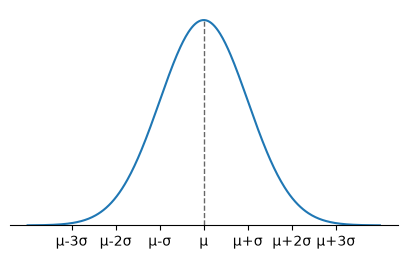

In [13]:
# Forma da densidade normal: simétrica em torno da média μ
z_graf = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(z_graf, norm.pdf(z_graf), color="tab:blue")
ax.vlines(0, 0, norm.pdf(0), color="0.4", ls="--", lw=1)
ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
ax.set_xticklabels(["μ-3σ", "μ-2σ", "μ-σ", "μ", "μ+σ", "μ+2σ", "μ+3σ"])
ax.set_yticks([])
ax.set_ylim(bottom=0)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

#### Propriedades:
- A distribuição é simétrica em torno da média, assim, as medidas de tendência central (média, mediana e moda) apresentam o mesmo valor.
- A distribuição normal fica delimitada pelo seu desvio padrão e sua média. Para cada combinação de valores de média e desvio padrão gera uma Distribuição Normal diferente;
- A área sob a curva corresponde à 1.
- O ponto de máximo da curva da distribuição normal ocorre quando x = μ, ou seja, em torno da média registra-se uma probabilidade maior de ocorrência. À medida que nos afastamos da média, as probabilidades de ocorrência vão diminuindo.
- Se X tiver a distribuição normal com média = 0 e variância = 1, ou seja, X ~ N (0,1), diremos que X possui a distribuição normal reduzida ou distribuição normal padrão. Isto é, sua função densidade de probabilidade pode ser escrita como:

$$f(x) = \frac{1}{\sqrt{2\pi}} e^{-\frac{x^2}{2}}$$

A integral da função densidade de probabilidade da distribuição normal, não pode ser avaliada pelo método tradicional (teorema fundamental do cálculo). Ela só pode ser calculada por métodos numéricos. E por isso ela é encontrada tabelada em qualquer livro texto de Probabilidade ou Estatística.

A Figura a seguir apresenta três curvas distintas, com mesmo desvio padrão, porém com médias diferentes. Distribuição Normal com desvio padrão σ=1 e médias μ=0, μ=1 e μ=2.

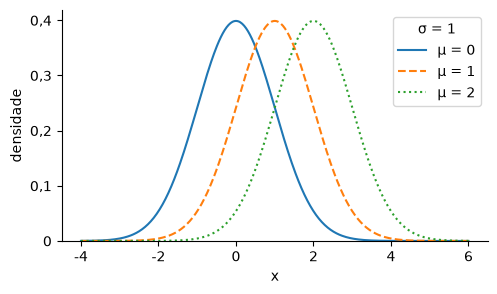

In [14]:
# Normais com desvio padrão 1 e médias 0, 1 e 2: a curva só se desloca
x_graf = np.linspace(-4, 6, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for mu_graf, estilo in ((0, "-"), (1, "--"), (2, ":")):
    ax.plot(x_graf, norm.pdf(x_graf, mu_graf, 1), ls=estilo, label=f"μ = {mu_graf}")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend(title="σ = 1")
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

A Figura a seguir apresenta três curvas distintas, com a mesma média, porém com desvios diferentes. Distribuições com média μ=0 e desvios diferentes σ=1, σ=2 e σ=3.

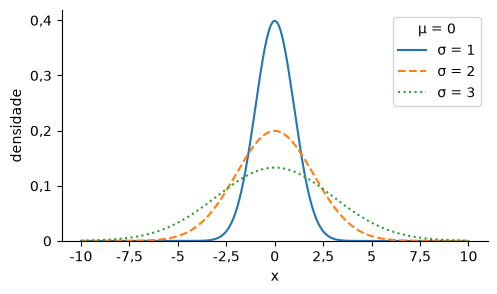

In [15]:
# Normais com média 0 e desvios padrão 1, 2 e 3: quanto maior σ, mais achatada
x_graf = np.linspace(-10, 10, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for sigma_graf, estilo in ((1, "-"), (2, "--"), (3, ":")):
    ax.plot(x_graf, norm.pdf(x_graf, 0, sigma_graf), ls=estilo, label=f"σ = {sigma_graf}")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend(title="μ = 0")
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

#### Regra de 2σ
No caso de uma distribuição normal N (μ;σ²), existe uma regra simples e muito útil. Qualquer que sejam os valores dos parâmetros, a área (e portanto, a probabilidade) que fica entre μ-σ e μ+σ é aproximadamente igual a 0,68. A área que fica localizada a dois σ de μ (isto é, a área entre μ-2σ e μ+2σ) é aproximadamente igual a 0,95. A uma distância de 3σ de μ fica uma área (e probabilidade) de 0,997, aproximadamente. Assim, é de 5% a chance de um valor selecionado de uma N (μ;σ²) se afastar por mais de 2σ de μ. A chance de se afastar mais de 3σ é bastante pequena.

#### Distribuição Normal Padrão
O cálculo de probabilidades, para variáveis adequadamente descritas pela distribuição
normal, é realizado por meio da distribuição normal padrão. A variável aleatória Z tem distribuição normal padrão, ou seja, Z ~ N (0, 1). Para obter tal distribuição, isto é, quando se tem uma variável X com distribuição normal com média μ diferente de 0 (zero) e/ou desvio padrão σ diferente de 1 (um), devemos reduzi-la a uma variável Z, efetuando o seguinte cálculo:

$$z = \frac{x - \mu}{\sigma}$$

Onde, z é o valor da variável normal padronizada Z, x é o valor da variável normal X; μ
é a média da variável aleatória X e σ é o desvio padrão da variável aleatória X.

Existem vários tipos de tabelas que nos fornecem as probabilidades sob a curva normal padrão. A tabela que vamos utilizar é aquela que fornece a probabilidade da variável Z assumir um valor entre zero e um particular valor z.

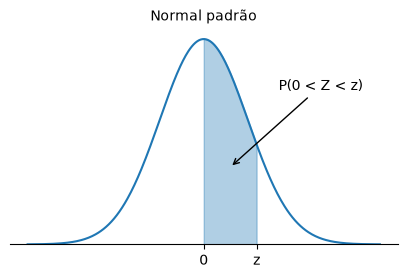

In [16]:
# A tabela usada a seguir dá a área entre 0 e um valor z positivo
z_graf = np.linspace(-4, 4, 400)
z_ilustrativo = 1.2
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(z_graf, norm.pdf(z_graf), color="tab:blue")
z_area = np.linspace(0, z_ilustrativo, 200)
ax.fill_between(z_area, norm.pdf(z_area), color="tab:blue", alpha=0.35)
ax.annotate("P(0 < Z < z)", xy=(0.6, 0.15), xytext=(1.7, 0.3), arrowprops=dict(arrowstyle="->"))
ax.set_xticks([0, z_ilustrativo])
ax.set_xticklabels(["0", "z"])
ax.set_yticks([])
ax.set_ylim(bottom=0)
ax.set_title("Normal padrão", fontsize=10)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

| z   | 0      | 1      | 2      | 3      | 4      | 5      | 6      | 7      | 8      | 9      |
|-----|--------|--------|--------|--------|--------|--------|--------|--------|--------|--------|
| 0,0 | 0,0000 | 0,0040 | 0,0080 | 0,0120 | 0,0160 | 0,0199 | 0,0239 | 0,0279 | 0,0319 | 0,0359 |
| 0,1 | 0,0398 | 0,0438 | 0,0478 | 0,0517 | 0,0557 | 0,0596 | 0,0636 | 0,0675 | 0,0714 | 0,0753 |
| 0,2 | 0,0793 | 0,0832 | 0,0871 | 0,0910 | 0,0948 | 0,0987 | 0,1026 | 0,1064 | 0,1103 | 0,1141 |
| 0,3 | 0,1179 | 0,1217 | 0,1255 | 0,1293 | 0,1331 | 0,1368 | 0,1406 | 0,1443 | 0,1480 | 0,1517 |
| 0,4 | 0,1554 | 0,1591 | 0,1628 | 0,1664 | 0,1700 | 0,1736 | 0,1772 | 0,1808 | 0,1844 | 0,1879 |
| 0,5 | 0,1915 | 0,1950 | 0,1985 | 0,2019 | 0,2054 | 0,2088 | 0,2123 | 0,2157 | 0,2190 | 0,2224 |
| 0,6 | 0,2257 | 0,2291 | 0,2324 | 0,2357 | 0,2389 | 0,2422 | 0,2454 | 0,2486 | 0,2517 | 0,2549 |
| 0,7 | 0,2580 | 0,2611 | 0,2642 | 0,2673 | 0,2704 | 0,2734 | 0,2764 | 0,2794 | 0,2823 | 0,2852 |
| 0,8 | 0,2881 | 0,2910 | 0,2939 | 0,2967 | 0,2995 | 0,3023 | 0,3051 | 0,3078 | 0,3106 | 0,3133 |
| 0,9 | 0,3159 | 0,3186 | 0,3212 | 0,3238 | 0,3264 | 0,3289 | 0,3315 | 0,3340 | 0,3365 | 0,3389 |
| 1,0 | 0,3413 | 0,3438 | 0,3461 | 0,3485 | 0,3508 | 0,3531 | 0,3554 | 0,3577 | 0,3599 | 0,3621 |
| 1,1 | 0,3643 | 0,3665 | 0,3686 | 0,3708 | 0,3729 | 0,3749 | 0,3770 | 0,3790 | 0,3810 | 0,3830 |
| 1,2 | 0,3849 | 0,3869 | 0,3888 | 0,3907 | 0,3925 | 0,3944 | 0,3962 | 0,3980 | 0,3997 | 0,4015 |
| 1,3 | 0,4032 | 0,4049 | 0,4066 | 0,4082 | 0,4099 | 0,4115 | 0,4131 | 0,4147 | 0,4162 | 0,4177 |
| 1,4 | 0,4192 | 0,4207 | 0,4222 | 0,4236 | 0,4251 | 0,4265 | 0,4279 | 0,4292 | 0,4306 | 0,4319 |
| 1,5 | 0,4332 | 0,4345 | 0,4357 | 0,4370 | 0,4382 | 0,4394 | 0,4406 | 0,4418 | 0,4429 | 0,4441 |
| 1,6 | 0,4452 | 0,4463 | 0,4474 | 0,4484 | 0,4495 | 0,4505 | 0,4515 | 0,4525 | 0,4535 | 0,4545 |
| 1,7 | 0,4554 | 0,4564 | 0,4573 | 0,4582 | 0,4591 | 0,4599 | 0,4608 | 0,4616 | 0,4625 | 0,4633 |
| 1,8 | 0,4641 | 0,4649 | 0,4656 | 0,4664 | 0,4671 | 0,4678 | 0,4686 | 0,4693 | 0,4699 | 0,4706 |
| 1,9 | 0,4713 | 0,4719 | 0,4726 | 0,4732 | 0,4738 | 0,4744 | 0,4750 | 0,4756 | 0,4761 | 0,4767 |
| 2,0 | 0,4772 | 0,4778 | 0,4783 | 0,4788 | 0,4793 | 0,4798 | 0,4803 | 0,4808 | 0,4812 | 0,4817 |
| 2,1 | 0,4821 | 0,4826 | 0,4830 | 0,4834 | 0,4838 | 0,4842 | 0,4846 | 0,4850 | 0,4854 | 0,4857 |
| 2,2 | 0,4861 | 0,4864 | 0,4868 | 0,4871 | 0,4875 | 0,4878 | 0,4881 | 0,4884 | 0,4887 | 0,4890 |
| 2,3 | 0,4893 | 0,4896 | 0,4898 | 0,4901 | 0,4904 | 0,4906 | 0,4909 | 0,4911 | 0,4913 | 0,4916 |
| 2,4 | 0,4918 | 0,4920 | 0,4922 | 0,4925 | 0,4927 | 0,4929 | 0,4931 | 0,4932 | 0,4934 | 0,4936 |
| 2,5 | 0,4938 | 0,4940 | 0,4941 | 0,4943 | 0,4945 | 0,4946 | 0,4948 | 0,4949 | 0,4951 | 0,4952 |
| 2,6 | 0,4953 | 0,4955 | 0,4956 | 0,4957 | 0,4959 | 0,4960 | 0,4961 | 0,4962 | 0,4963 | 0,4964 |
| 2,7 | 0,4965 | 0,4966 | 0,4967 | 0,4968 | 0,4969 | 0,4970 | 0,4971 | 0,4972 | 0,4973 | 0,4974 |
| 2,8 | 0,4974 | 0,4975 | 0,4976 | 0,4977 | 0,4977 | 0,4978 | 0,4979 | 0,4979 | 0,4980 | 0,4981 |
| 2,9 | 0,4981 | 0,4982 | 0,4982 | 0,4983 | 0,4984 | 0,4984 | 0,4985 | 0,4985 | 0,4986 | 0,4986 |
| 3,0 | 0,4987 | 0,4987 | 0,4987 | 0,4988 | 0,4988 | 0,4989 | 0,4989 | 0,4989 | 0,4990 | 0,4990 |
| 3,1 | 0,4990 | 0,4991 | 0,4991 | 0,4991 | 0,4992 | 0,4992 | 0,4992 | 0,4992 | 0,4993 | 0,4993 |
| 3,2 | 0,4993 | 0,4993 | 0,4994 | 0,4994 | 0,4994 | 0,4994 | 0,4994 | 0,4995 | 0,4995 | 0,4995 |
| 3,3 | 0,4995 | 0,4995 | 0,4995 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4996 | 0,4997 |
| 3,4 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4997 | 0,4998 |
| 3,5 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 | 0,4998 |

#### Exemplos:
Dado que Z é uma variável aleatória normal padrão, ou seja, μ=0 e σ=1, ou então, Z ~ N (0, 1), calcule as probabilidades à seguir:

- a) P(-1,5 < Z < 0)

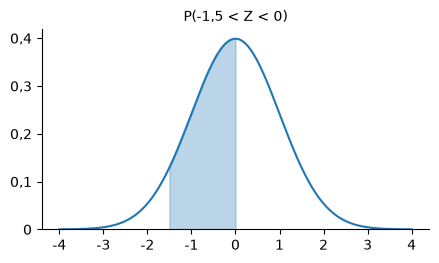

In [17]:
area_normal(-1.5, 0, "P(-1,5 < Z < 0)")

Consulta à tabela da normal padrão: linha 1,5 e coluna 0 → 0,4332 (área entre 0 e 1,5). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    Já que a curva da distribuição normal é simétrica em torno da média, então 
    P(-1,5<Z<0) = P(0<Z<1,5) = 0,4332 

In [18]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.5) = {:.4f}".format(norm.cdf(1.5) - 0.5))

P(0 < Z < 1.5) = 0.4332


In [12]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.5
b_Nor = 0

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.4331927987311419

- b) P(0 < Z < 0,83)

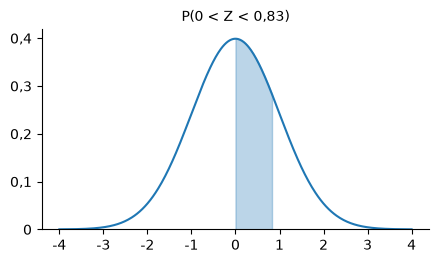

In [19]:
area_normal(0, 0.83, "P(0 < Z < 0,83)")

Consulta à tabela da normal padrão: linha 0,8 e coluna 3 → 0,2967 (área entre 0 e 0,83). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<0,83)=0,2967

In [20]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.83) = {:.4f}".format(norm.cdf(0.83) - 0.5))

P(0 < Z < 0.83) = 0.2967


In [20]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = 0
b_Nor = 0.83

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.29673060817193164

- c) P(Z > -0,23)

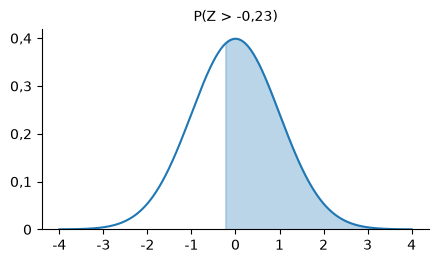

In [21]:
area_normal(-0.23, np.inf, "P(Z > -0,23)")

Consulta à tabela da normal padrão: linha 0,2 e coluna 3 → 0,0910 (área entre 0 e 0,23). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(-0,23<Z<0) = 0,0910
    Para encontrar P(Z>-0,23) = P(-0,23<Z<0) + 0,5 = 0,5910
    Foi necessário somar 0,5 à probabilidade porque P(Z>0) =0,5.

In [22]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.23) = {:.4f}".format(norm.cdf(0.23) - 0.5))

P(0 < Z < 0.23) = 0.0910


In [24]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -0.23
b_Nor = np.inf #infinito positivo

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.5909541151420056

- d) P(Z < 1,20)

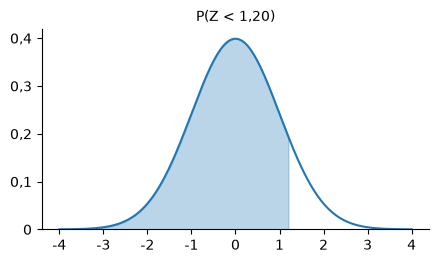

In [23]:
area_normal(-np.inf, 1.2, "P(Z < 1,20)")

Consulta à tabela da normal padrão: linha 1,2 e coluna 0 → 0,3849 (área entre 0 e 1,20). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<1,20) = 0,3849
    Para encontrar P(Z<1,20) = P(0<Z<1,20) + 0,5 = 0,8849.
    Foi necessário somar 0,5 à probabilidade porque P(Z<0) =0,5.

In [24]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.20) = {:.4f}".format(norm.cdf(1.20) - 0.5))

P(0 < Z < 1.20) = 0.3849


In [28]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -np.inf #infinito negativo
b_Nor = 1.2

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8849303297782929

- e) P(-1,98 < Z < 0,49)

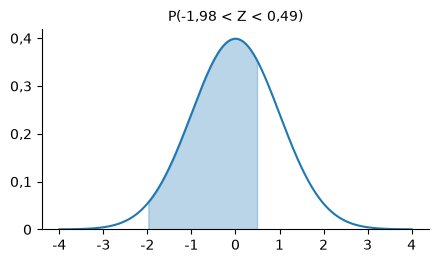

In [25]:
area_normal(-1.98, 0.49, "P(-1,98 < Z < 0,49)")

Consulta à tabela da normal padrão: linha 0,4 e coluna 9 → 0,1879 (área entre 0 e 0,49); linha 1,9 e coluna 8 → 0,4761 (área entre 0 e 1,98). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<0,49) = 0,1879
    P(-1,98<Z<0) = 0,4761
    Para encontrar P(-1,98<Z<0,49) = P(-1,98<Z<0) + P(0<Z<0,49) = 0,6640.

In [26]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.49) = {:.4f}".format(norm.cdf(0.49) - 0.5))
print("P(0 < Z < 1.98) = {:.4f}".format(norm.cdf(1.98) - 0.5))

P(0 < Z < 0.49) = 0.1879
P(0 < Z < 1.98) = 0.4761


In [29]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.98
b_Nor = 0.49

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.6640812862411007

- f) P(0,52 < Z < 1,22)

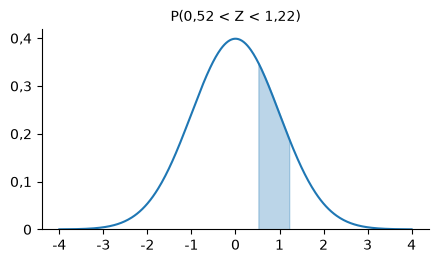

In [27]:
area_normal(0.52, 1.22, "P(0,52 < Z < 1,22)")

Consulta à tabela da normal padrão: linha 0,5 e coluna 2 → 0,1985 (área entre 0 e 0,52); linha 1,2 e coluna 2 → 0,3888 (área entre 0 e 1,22). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(0<Z<0,52) = 0,1985
    P(0<Z<1,22) = 0,3888
    Para encontrar P(0,52<Z<1,22) = P(0<Z<1,22) - P(0<Z<0,52) = 0,1903.

In [28]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 0.52) = {:.4f}".format(norm.cdf(0.52) - 0.5))
print("P(0 < Z < 1.22) = {:.4f}".format(norm.cdf(1.22) - 0.5))

P(0 < Z < 0.52) = 0.1985
P(0 < Z < 1.22) = 0.3888


In [30]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = 0.52
b_Nor = 1.22

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.1902993500991316

- g) P(-1,75 < Z < -1,04)

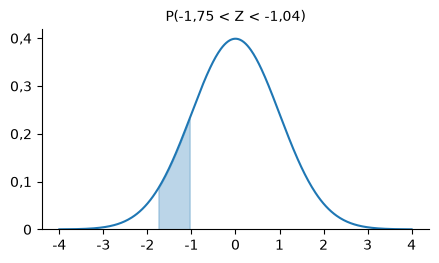

In [29]:
area_normal(-1.75, -1.04, "P(-1,75 < Z < -1,04)")

Consulta à tabela da normal padrão: linha 1,7 e coluna 5 → 0,4599 (área entre 0 e 1,75); linha 1,0 e coluna 4 → 0,3508 (área entre 0 e 1,04). Os mesmos valores, calculados com o `scipy`, estão na célula de código abaixo.

Resposta:

    P(-1,75<Z<0)=0,4599
    P(-1,04<Z<0)=0,3508
    Para encontrar P(-1,75<Z<-1,04) = P(-1,75<Z<0) - P(-1,04<Z<0) = 0,1091.

In [30]:
# Área entre 0 e z na normal padrão (o valor que a tabela fornece)
from scipy.stats import norm

print("P(0 < Z < 1.75) = {:.4f}".format(norm.cdf(1.75) - 0.5))
print("P(0 < Z < 1.04) = {:.4f}".format(norm.cdf(1.04) - 0.5))

P(0 < Z < 1.75) = 0.4599
P(0 < Z < 1.04) = 0.3508


In [31]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Definindo os limites inferior e superior
a_Nor = -1.75
b_Nor = -1.04

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.10911079346716433

#### Exemplo:
Suponha que as medidas da corrente em um pedaço de fio sigam a distribuição normal, com um média de 10 miliamperes e uma variância de 5 miliamperes. Qual a probabilidade:

- a) Da medida da corrente ser de no máximo 12 miliamperes.
    Graficamente, a probabilidade desejada pode ser representada da seguinte maneira:

$$P(X \le 12) = P\left(Z \le \frac{12 - 10}{\sqrt{5}}\right) = P(Z \le 0{,}89) = 0{,}5 + 0{,}3133 = 0{,}8133$$

(Como a variância é 5, o desvio padrão é $\sqrt{5}$; o valor de $z$ foi arredondado para duas casas, como na tabela.)

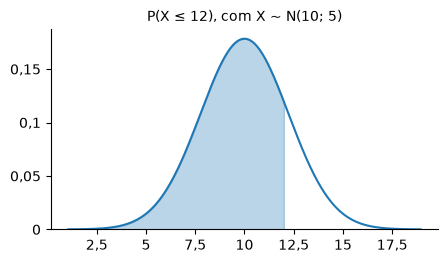

In [31]:
area_normal(-np.inf, 12, "P(X ≤ 12), com X ~ N(10; 5)", mu=10, sigma=np.sqrt(5))

In [75]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 10
Variancia_Nor = 5


#Cálculo solicitado no enunciado P(X <= 12)
x_Nor_1 = -np.inf
x_Nor_2 = 12


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  0.89


In [76]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8132670569628278

- b) Da medida da corrente ser de pelo menos 13 miliamperes.

$$P(X \ge 13) = P\left(Z \ge \frac{13 - 10}{\sqrt{5}}\right) = P(Z \ge 1{,}34) = 0{,}5 - 0{,}4099 = 0{,}0901$$

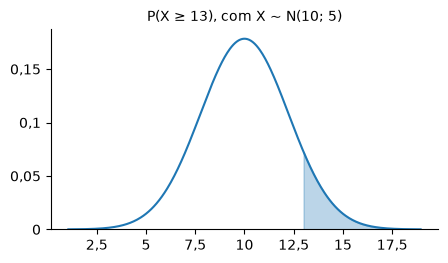

In [32]:
area_normal(13, np.inf, "P(X ≥ 13), com X ~ N(10; 5)", mu=10, sigma=np.sqrt(5))

In [77]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 10
Variancia_Nor = 5


#Cálculo solicitado no enunciado P(X >= 13)
x_Nor_1 = 13
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  1.34
Z superior:  inf


In [78]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.09012267246445248

- c) Um valor entre 9 e 11 miliamperes.

$$P(9 < X < 11) = P\left(\frac{9 - 10}{\sqrt{5}} < Z < \frac{11 - 10}{\sqrt{5}}\right) = P(-0{,}45 < Z < 0{,}45) = 2 \cdot 0{,}17364 \approx 0{,}3473$$

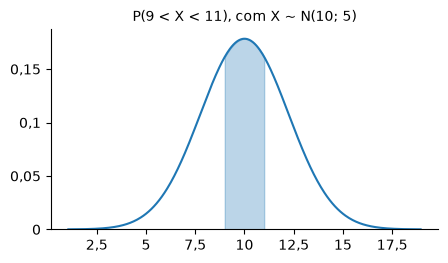

In [33]:
area_normal(9, 11, "P(9 < X < 11), com X ~ N(10; 5)", mu=10, sigma=np.sqrt(5))

In [79]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 10
Variancia_Nor = 5


#Cálculo solicitado no enunciado P(9 < X < 11)
x_Nor_1 = 9
x_Nor_2 = 11


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.45
Z superior:  0.45


In [80]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.34728955942416

- d) Maior do que 8 miliamperes.

$$P(X > 8) = P\left(Z > \frac{8 - 10}{\sqrt{5}}\right) = P(Z > -0{,}89) = 0{,}5 + 0{,}3133 = 0{,}8133$$

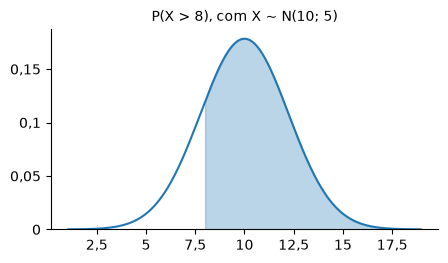

In [34]:
area_normal(8, np.inf, "P(X > 8), com X ~ N(10; 5)", mu=10, sigma=np.sqrt(5))

In [83]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 10
Variancia_Nor = 5


#Cálculo solicitado no enunciado P(X > 8)
x_Nor_1 = 8
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.89
Z superior:  inf


In [84]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8132670569628278

#### Exercício 3:
Considere que a pontuação obtida por diferentes candidatos em um concurso público segue uma distribuição aproximadamente normal, com média igual a 140 pontos e desvio padrão igual a 20 pontos. Suponha que um candidato é escolhido ao acaso. Calcule as probabilidades a seguir:

- a) Apresentar uma pontuação entre 140 e 165,6. R:0,3997

In [87]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(140 < X < 165.6)
x_Nor_1 = 140
x_Nor_2 = 165.6


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  0.0
Z superior:  1.28


In [88]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.399727432045558

- b) Apresentar uma pontuação entre 127,4 e 140. R:0,2357

In [89]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(127.4 < X < 140)
x_Nor_1 = 127.4
x_Nor_2 = 140


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.63
Z superior:  0.0


In [90]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.23565270788432247

- c) Apresentar uma pontuação entre 117,2 e 157. R:0,6752

In [93]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(117.2 < X < 157)
x_Nor_1 = 117.2
x_Nor_2 = 157


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.14
Z superior:  0.85


In [94]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.6751943063145093

- d) Apresentar uma pontuação inferior a 127. R:0,2578

In [95]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 127)
x_Nor_1 = -np.inf
x_Nor_2 = 127


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  -0.65


In [96]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.2578461108058647

- e) Apresentar uma pontuação superior a 174,2. R:0,0436

In [97]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X > 174.2)
x_Nor_1 = 174.2
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  1.71
Z superior:  inf


In [98]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.043632936524031905

- f) Apresentar uma pontuação inferior a 167,4. R:0,9147

In [99]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 167.4)
x_Nor_1 = -np.inf
x_Nor_2 = 167.4


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  1.37


In [100]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.914656549178033

- g) Apresentar uma pontuação entre 155,4 e 168,4. R:0,1428

In [101]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 140
Desvio_P_Nor = 20
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(155.4 < X < 168.4)
x_Nor_1 = 155.4
x_Nor_2 = 168.4


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  0.77
Z superior:  1.42


In [102]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.14284610581610319

#### Exercício 4:
As vendas diárias de um mercado de bairro seguem, aproximadamente, uma distribuição normal, com média igual RS 5000,00 e desvio padrão igual a RS 2000,00. Calcule a probabilidade de que, em um determinado dia, as vendas:

- a) Sejam superiores a 3.500,00? R:0,7734

In [104]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 5000
Desvio_P_Nor = 2000
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X > 3500)
x_Nor_1 = 3500
x_Nor_2 = np.inf


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.75
Z superior:  inf


In [105]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.773372647623133

- b) Sejam inferiores a 3.000,00? R:0,1587

In [106]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 5000
Desvio_P_Nor = 2000
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(X < 3000)
x_Nor_1 = -np.inf
x_Nor_2 = 3000


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -inf
Z superior:  -1.0


In [107]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.15865525393145707

- c) Estejam entre 3.800,00 e 5.300,00? R:0,2854

In [108]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 5000
Desvio_P_Nor = 2000
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(3800 < X < 5300)
x_Nor_1 = 3800
x_Nor_2 = 5300


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -0.6
Z superior:  0.15


In [109]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.285364574620169

- d) Estejam entre 2.100,00 e 7.800,00? R:0,8457

In [110]:
#Padronizando a variável X para converter para Z.
import numpy as np

#Definindo média e variância de acordo com enunciado
Media_Nor = 5000
Desvio_P_Nor = 2000
Variancia_Nor = Desvio_P_Nor**2


#Cálculo solicitado no enunciado P(2100 < X < 7800)
x_Nor_1 = 2100
x_Nor_2 = 7800


#Calculando valor Z para limite inferior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_1 == 0 or x_Nor_1 == -np.inf:
    a_Nor = x_Nor_1
else:
    a_Nor = round((x_Nor_1 - Media_Nor) / (Variancia_Nor**0.5), 2)

#Calculando valor Z para limite superior (escolhe entre calcular ou pegar valor direto quando 0 ou inf)
if x_Nor_2 == 0 or x_Nor_2 == np.inf:
    b_Nor = x_Nor_2
else:
    b_Nor = round((x_Nor_2 - Media_Nor) / (Variancia_Nor**0.5), 2)

    
print("Z inferior: ",a_Nor)
print("Z superior: ",b_Nor)

Z inferior:  -1.45
Z superior:  1.4


In [111]:
#Definindo a função normal padrão e calculando a Probabilidade de z.
from scipy.integrate import quad
import numpy as np

def F_Normal_Padrao(z):
    constant = 1.0 / np.sqrt(2*np.pi)
    return(constant * np.exp((-z**2) / 2.0) )

#Calculando a probabilidade de z de a até b.
P_Nor, _ = quad(F_Normal_Padrao, a_Nor, b_Nor)
P_Nor

0.8457140811565805